# PathSnap - all notebooks (01-06) in one, for Kaggle
Input needed: the dataset containing the `Student folder` (`train/` + `student_test/`). Run all cells top to bottom.
Cells below are the original notebooks 01-06, unchanged, in order.

In [1]:
# ===== KAGGLE SETUP (added; does not touch any project logic) =====
# Writes the project's src/ files (verbatim) into /kaggle/working and finds the data folder automatically.
import os, sys, subprocess
WORK = "/kaggle/working/pathsnap_project"
SRC_FILES = {'config.py': '"""\nCentral configuration.  >>> EDIT DATA_ROOT ONCE <<<  (or set env var PATHSNAP_DATA)\n\nDATA_ROOT must point at the UNZIPPED \'Student folder\' that contains:\n    train/           (80 trips)\n    student_test/    (10 trips)\nEvaluator data is NEVER placed here - it is only given to the API at final evaluation.\n"""\nimport os\n\nDATA_ROOT = os.environ.get("PATHSNAP_DATA", r"C:\\PathSnap\\Student folder")   # <-- EDIT ME\n\nPROJECT_ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))\nTRAIN_DIR = os.path.join(DATA_ROOT, "train")\nTEST_DIR = os.path.join(DATA_ROOT, "student_test")\n\nARTIFACTS = os.path.join(PROJECT_ROOT, "artifacts")\nDATA_OUT = os.path.join(ARTIFACTS, "data")\nOUTPUTS = os.path.join(PROJECT_ROOT, "outputs")\nFIG_DIR = os.path.join(OUTPUTS, "figures")\nMAP_DIR = os.path.join(OUTPUTS, "maps")\nfor _d in (ARTIFACTS, DATA_OUT, OUTPUTS, FIG_DIR, MAP_DIR):\n    os.makedirs(_d, exist_ok=True)\n\nTRAIN_TABLE = os.path.join(DATA_OUT, "train_candidates.parquet")\nTEST_TABLE = os.path.join(DATA_OUT, "student_test_candidates.parquet")\nQUALITY_CSV = os.path.join(ARTIFACTS, "trip_quality.csv")\n\nSEED = 42\n\n# ---- candidate generation / labelling (fixed in notebook 02 from TRAIN data only) ----\nRADIUS_M = 50.0          # candidate search radius\nK_MAX = 15               # max candidates per GPS point\nSKIP_PEN = 1.0           # DP alignment: metres charged per skipped reference arc\nQUALITY_MAX_MEDIAN_RESID_M = 30.0   # trips whose reference route does not fit their GPS are not used for training\n\n# ---- model experimentation ----\nSTRIDE = 6               # use every 6th GPS point of the training trips for model comparison (1 Hz data is very redundant)\nN_SPLITS = 3             # GroupKFold folds (by trip) for comparison\nSTRIDE_FINAL = 2         # denser sampling for the final refit\n\nBASELINE_LGBM = dict(n_estimators=300, learning_rate=0.05, num_leaves=63, random_state=SEED,\n                     verbose=-1, n_jobs=-1)\n', 'pathsnap_core.py': '"""\nPathSnap core library: I/O, projection, reference-label alignment, candidate\ngeneration, feature engineering and HMM/Viterbi decoding.\n\nEvery notebook, the API and the evaluation scripts import from here so that\ntraining-time and inference-time processing are IDENTICAL.\n"""\nimport os\nimport numpy as np\nimport pandas as pd\nfrom pyproj import Transformer\nfrom shapely import STRtree, linestrings, points as shp_points\n\n\n# ----------------------------------------------------------------------------\n# 1. I/O\n# ----------------------------------------------------------------------------\ndef list_trips(partition_dir):\n    """Return sorted trip ids (folder names) inside a partition folder."""\n    return sorted(d for d in os.listdir(partition_dir)\n                  if os.path.isdir(os.path.join(partition_dir, d)))\n\n\ndef load_trip(partition_dir, trip_id, with_route=True):\n    """Load one trip. .route is optional so the same function works for inference."""\n    base = os.path.join(partition_dir, trip_id, trip_id)\n    track = pd.read_csv(base + ".track", sep=r"\\s+", header=None, names=["lon", "lat", "t"])\n    nodes = pd.read_csv(base + ".nodes", sep=r"\\s+", header=None, names=["lon", "lat"])\n    arcs = pd.read_csv(base + ".arcs", sep=r"\\s+", header=None, names=["u", "v"])\n    route = None\n    if with_route and os.path.exists(base + ".route"):\n        route = pd.read_csv(base + ".route", header=None).iloc[:, 0].to_numpy(dtype=np.int64)\n    return dict(trip_id=trip_id, track=track, nodes=nodes, arcs=arcs, route=route)\n\n\n# ----------------------------------------------------------------------------\n# 2. Local metric projection (azimuthal equidistant centred on the trip)\n#    Each trip lives in a different city, so one global CRS is wrong; an AEQD\n#    centred on the trip centroid keeps distances accurate to well under a\n#    metre for trips spanning tens of km.\n# ----------------------------------------------------------------------------\ndef make_projector(lon0, lat0):\n    return Transformer.from_crs(\n        4326, f"+proj=aeqd +lat_0={lat0} +lon_0={lon0} +units=m +ellps=WGS84", always_xy=True)\n\n\nclass TripGeometry:\n    """Projected view of one trip: GPS xy, arc endpoints, adjacency and a spatial index."""\n\n    def __init__(self, trip):\n        tr, nd, ar = trip["track"], trip["nodes"], trip["arcs"]\n        self.trip_id = trip["trip_id"]\n        self.proj = make_projector(tr.lon.mean(), tr.lat.mean())\n        self.gx, self.gy = self.proj.transform(tr.lon.to_numpy(), tr.lat.to_numpy())\n        self.gx, self.gy = np.asarray(self.gx), np.asarray(self.gy)\n        self.t = tr.t.to_numpy(dtype=float)\n        nx, ny = self.proj.transform(nd.lon.to_numpy(), nd.lat.to_numpy())\n        nx, ny = np.asarray(nx), np.asarray(ny)\n        self.u = ar.u.to_numpy(dtype=np.int64)\n        self.v = ar.v.to_numpy(dtype=np.int64)\n        self.ax, self.ay = nx[self.u], ny[self.u]          # arc start\n        self.bx, self.by = nx[self.v], ny[self.v]          # arc end\n        self.alen = np.hypot(self.bx - self.ax, self.by - self.ay)\n        self.n_nodes, self.n_arcs, self.n_gps = len(nd), len(ar), len(tr)\n        self.nodes_lonlat = nd[["lon", "lat"]].to_numpy()\n        self._tree = None\n        # adjacency: arcs leaving each node (CSR style)\n        order = np.argsort(self.u, kind="stable")\n        self._out_sorted = order\n        self._out_ptr = np.searchsorted(self.u[order], np.arange(self.n_nodes + 1))\n        self.out_deg = np.diff(self._out_ptr)\n        self.in_deg = np.bincount(self.v, minlength=self.n_nodes)\n        # reverse-arc lookup: arc id of (v,u) or -1\n        key = self.u * self.n_nodes + self.v\n        rkey = self.v * self.n_nodes + self.u\n        srt = np.argsort(key)\n        pos = np.clip(np.searchsorted(key[srt], rkey), 0, len(key) - 1)\n        hit = key[srt][pos] == rkey\n        self.rev = np.where(hit, srt[pos], -1)\n\n    def arcs_from_node(self, node):\n        return self._out_sorted[self._out_ptr[node]:self._out_ptr[node + 1]]\n\n    @property\n    def tree(self):\n        if self._tree is None:\n            geoms = linestrings(np.stack([np.c_[self.ax, self.ay], np.c_[self.bx, self.by]], axis=1))\n            self._tree = STRtree(geoms)\n        return self._tree\n\n\ndef seg_dist(px, py, ax, ay, bx, by):\n    """Distance from points to segments + projection fraction (vectorised, broadcastable)."""\n    dx, dy = bx - ax, by - ay\n    L2 = dx * dx + dy * dy\n    t = np.where(L2 > 1e-9, ((px - ax) * dx + (py - ay) * dy) / np.maximum(L2, 1e-9), 0.0)\n    t = np.clip(t, 0.0, 1.0)\n    return np.hypot(px - (ax + t * dx), py - (ay + t * dy)), t\n\n\n# ----------------------------------------------------------------------------\n# 3. Reference per-point labels.  .route gives an ARC sequence, NOT per-GPS-point\n#    labels, so we align the GPS sequence to the reference arc sequence with a\n#    monotone DP (stay/advance are free, skipping arcs costs `skip_pen` m per arc).\n#    Used ONLY to create training labels / server-side scoring.\n# ----------------------------------------------------------------------------\ndef align_points_to_route(geo, route, skip_pen=1.0, chunk=2000):\n    m, n = len(route), geo.n_gps\n    ax, ay, bx, by = geo.ax[route], geo.ay[route], geo.bx[route], geo.by[route]\n    D = np.empty((n, m), dtype=np.float32)\n    for s in range(0, n, chunk):\n        e = min(n, s + chunk)\n        d, _ = seg_dist(geo.gx[s:e, None], geo.gy[s:e, None], ax[None], ay[None], bx[None], by[None])\n        D[s:e] = d\n    idx = np.arange(m, dtype=np.float32)\n    ar = np.arange(m, dtype=np.int32)\n    best = D[0] + skip_pen * idx                     # starting late is penalised\n    bp = np.zeros((n, m), dtype=np.int32)\n    for i in range(1, n):\n        v = best - skip_pen * idx\n        acc = np.minimum.accumulate(v)\n        arg = np.maximum.accumulate(np.where(v == acc, ar, 0)).astype(np.int32)\n        jump = np.full(m, np.inf, dtype=np.float32)\n        jump[1:] = acc[:-1] + skip_pen * (idx[1:] - 1)   # k=j-1 -> zero penalty\n        jarg = np.zeros(m, dtype=np.int32)\n        jarg[1:] = arg[:-1]\n        use_jump = jump < best\n        bp[i] = np.where(use_jump, jarg, ar)\n        best = np.where(use_jump, jump, best) + D[i]\n    best = best + skip_pen * (m - 1 - idx)           # ending early is penalised\n    j = int(np.argmin(best))\n    path = np.empty(n, dtype=np.int64)\n    for i in range(n - 1, -1, -1):\n        path[i] = j\n        j = bp[i, j]\n    resid = D[np.arange(n), path]\n    return path, resid      # route[path[i]] = reference arc id of point i\n\n\n# ----------------------------------------------------------------------------\n# 4. Candidate generation + features\n# ----------------------------------------------------------------------------\nFEATURES = [\n    "dist", "dist_minus_min", "rank", "n_cands", "proj_frac", "arc_len",\n    "speed", "dt_prev", "hdg_cos", "hdg_sin", "hdg_abs", "along_disp", "along_disp_norm",\n    "dist_m10", "dist_m5", "dist_p5", "dist_p10", "dist_win_mean", "dist_win_max",\n    "has_rev", "rev_in_cands", "out_deg_v", "in_deg_u", "dist_to_end", "dist_to_start",\n]\n\n\ndef generate_candidates(geo, radius=50.0, k_max=15):\n    """For every GPS point return arcs within `radius` m (nearest k_max kept)."""\n    pts = shp_points(np.c_[geo.gx, geo.gy])\n    pi, ai = geo.tree.query(pts, predicate="dwithin", distance=radius)\n    d, fr = seg_dist(geo.gx[pi], geo.gy[pi], geo.ax[ai], geo.ay[ai], geo.bx[ai], geo.by[ai])\n    df = pd.DataFrame(dict(pt=pi.astype(np.int64), arc=ai.astype(np.int64), dist=d, proj_frac=fr))\n    df = df.sort_values(["pt", "dist"], kind="stable")\n    df["rank"] = df.groupby("pt").cumcount()\n    return df[df["rank"] < k_max].reset_index(drop=True)\n\n\ndef build_features(geo, cand):\n    """Add engineered features to the candidate table (vectorised)."""\n    n = geo.n_gps\n    gx, gy, t = geo.gx, geo.gy, geo.t\n    i = np.arange(n)\n\n    def sh(o):\n        return np.clip(i + o, 0, n - 1)\n\n    dx = gx[sh(2)] - gx[sh(-2)]\n    dy = gy[sh(2)] - gy[sh(-2)]\n    dtm = np.maximum(t[sh(2)] - t[sh(-2)], 1e-3)\n    step = np.hypot(dx, dy)\n    speed = step / dtm\n    dt_prev = np.r_[0.0, np.diff(t)]\n    wx = gx[sh(5)] - gx[sh(-5)]\n    wy = gy[sh(5)] - gy[sh(-5)]\n    p, a = cand["pt"].to_numpy(), cand["arc"].to_numpy()\n    ax, ay, bx, by = geo.ax[a], geo.ay[a], geo.bx[a], geo.by[a]\n    L = np.maximum(geo.alen[a], 1e-6)\n    ux, uy = (bx - ax) / L, (by - ay) / L\n    mv = step[p]\n    mvx = np.where(mv > 1e-6, dx[p] / np.maximum(mv, 1e-6), 0.0)\n    mvy = np.where(mv > 1e-6, dy[p] / np.maximum(mv, 1e-6), 0.0)\n    moving = speed[p] > 0.5\n    out = cand.copy()\n    out["dist_minus_min"] = out["dist"] - out.groupby("pt")["dist"].transform("min")\n    out["n_cands"] = out.groupby("pt")["arc"].transform("size")\n    out["arc_len"] = geo.alen[a]\n    out["speed"] = speed[p]\n    out["dt_prev"] = dt_prev[p]\n    out["hdg_cos"] = np.where(moving, mvx * ux + mvy * uy, 0.0)\n    sind = np.where(moving, mvx * uy - mvy * ux, 0.0)\n    out["hdg_sin"] = sind\n    out["hdg_abs"] = np.abs(sind)\n    along = wx[p] * ux + wy[p] * uy\n    wn = np.hypot(wx[p], wy[p])\n    out["along_disp"] = along\n    out["along_disp_norm"] = np.where(wn > 1.0, along / np.maximum(wn, 1e-6), 0.0)\n    ds = []\n    for o in (-10, -5, 5, 10):\n        q = sh(o)[p]\n        d, _ = seg_dist(gx[q], gy[q], ax, ay, bx, by)\n        ds.append(d)\n        out[f"dist_{\'m\' if o < 0 else \'p\'}{abs(o)}"] = d\n    allw = np.stack(ds + [out["dist"].to_numpy()], axis=1)\n    out["dist_win_mean"] = allw.mean(1)\n    out["dist_win_max"] = allw.max(1)\n    out["has_rev"] = (geo.rev[a] >= 0).astype(np.int8)\n    key = set(zip(p.tolist(), a.tolist()))\n    out["rev_in_cands"] = [int(rr >= 0 and (pp, rr) in key)\n                           for pp, rr in zip(p.tolist(), geo.rev[a].tolist())]\n    out["out_deg_v"] = geo.out_deg[geo.v[a]]\n    out["in_deg_u"] = geo.in_deg[geo.u[a]]\n    out["dist_to_start"] = out["proj_frac"] * geo.alen[a]\n    out["dist_to_end"] = (1 - out["proj_frac"]) * geo.alen[a]\n    return out\n\n\ndef trip_candidate_table(trip, radius=50.0, k_max=15, with_labels=True, skip_pen=1.0):\n    """Full per-trip pipeline -> (geometry, candidate table with features[, labels], ref arc/pt)."""\n    geo = TripGeometry(trip)\n    cand = build_features(geo, generate_candidates(geo, radius, k_max))\n    cand["trip_id"] = trip["trip_id"]\n    ref_arc = None\n    if with_labels and trip.get("route") is not None:\n        path, _ = align_points_to_route(geo, trip["route"], skip_pen)\n        ref_arc = trip["route"][path]\n        cand["label"] = (cand["arc"].to_numpy() == ref_arc[cand["pt"].to_numpy()]).astype(np.int8)\n    return geo, cand, ref_arc\n\n\n# ----------------------------------------------------------------------------\n# 5. HMM / Viterbi\n#    hidden state at time t = one of the candidate arcs of GPS point t\n#    emission   = log classifier probability  (scaled by w_emit)\n#    transition = f(network hops between arcs), U-turn penalty, gap reset\n# ----------------------------------------------------------------------------\nDEFAULT_HMM = dict(w_emit=1.0, hop_pen=1.0, unreach_pen=8.0, uturn_pen=6.0, stay_pen=0.0,\n                   max_hops=4, gap_s=30.0, p_floor=1e-4)\n\n\nclass HopOracle:\n    """Cached BFS: #hops from arc a to arc b (1 = b starts where a ends)."""\n\n    def __init__(self, geo, max_hops):\n        self.geo, self.H, self.cache = geo, max_hops, {}\n\n    def reach(self, a):\n        r = self.cache.get(a)\n        if r is None:\n            r = {}\n            frontier = [int(a)]\n            for h in range(1, self.H + 1):\n                nxt = []\n                for x in frontier:\n                    for y in self.geo.arcs_from_node(self.geo.v[x]):\n                        y = int(y)\n                        if y not in r:\n                            r[y] = h\n                            nxt.append(y)\n                frontier = nxt\n            self.cache[a] = r\n        return r\n\n\ndef viterbi_decode(geo, cand, prob, params=None):\n    """cand: candidate table sorted by pt; prob: P(candidate correct) per row.\n    Returns pred_arc[n_gps] (-1 where a point has no candidate) and diagnostics."""\n    P = {**DEFAULT_HMM, **(params or {})}\n    n = geo.n_gps\n    pt = cand["pt"].to_numpy()\n    arc = cand["arc"].to_numpy()\n    lp = np.log(np.clip(prob, P["p_floor"], 1.0)) * P["w_emit"]\n    starts = np.searchsorted(pt, np.arange(n + 1))\n    oracle = HopOracle(geo, int(P["max_hops"]))\n    pred = -np.ones(n, dtype=np.int64)\n    steps = [i for i in range(n) if starts[i + 1] > starts[i]]\n    if not steps:\n        return pred, dict(resets=0, no_valid_transition=0)\n    resets = dead = 0\n    back = []\n    prev_i = steps[0]\n    delta = lp[starts[prev_i]:starts[prev_i + 1]].copy()\n    for i in steps[1:]:\n        pa = arc[starts[prev_i]:starts[prev_i + 1]]\n        ca = arc[starts[i]:starts[i + 1]]\n        gap = geo.t[i] - geo.t[prev_i]\n        if gap > P["gap_s"]:                      # large gap: transition carries no information\n            T = np.zeros((len(pa), len(ca)))\n            resets += 1\n        else:\n            T = np.empty((len(pa), len(ca)))\n            for r, a in enumerate(pa):\n                reach = oracle.reach(a)\n                ra = geo.rev[a]\n                for c, b in enumerate(ca):\n                    if a == b:\n                        T[r, c] = -P["stay_pen"]\n                    elif b == ra:\n                        T[r, c] = -P["uturn_pen"]\n                    elif b in reach:\n                        T[r, c] = -P["hop_pen"] * reach[b]\n                    else:\n                        T[r, c] = -P["unreach_pen"]     # invalid (disconnected) -> heavy penalty, not -inf\n            dead += int(np.all(T <= -P["unreach_pen"]))\n        sc = delta[:, None] + T\n        bp = sc.argmax(0)\n        delta = sc[bp, np.arange(len(ca))] + lp[starts[i]:starts[i + 1]]\n        back.append(bp)\n        prev_i = i\n    k = int(delta.argmax())\n    seq = [k]\n    for bp in reversed(back):\n        k = int(bp[k])\n        seq.append(k)\n    seq = seq[::-1]\n    for si, i in enumerate(steps):\n        pred[i] = arc[starts[i] + seq[si]]\n    return pred, dict(resets=resets, no_valid_transition=dead)\n\n\ndef classifier_only_decode(geo, cand, prob):\n    """Argmax per point (observation-level top-1) -> pred_arc[n_gps]."""\n    pred = -np.ones(geo.n_gps, dtype=np.int64)\n    df = pd.DataFrame(dict(pt=cand["pt"].to_numpy(), arc=cand["arc"].to_numpy(), p=prob))\n    top = df.loc[df.groupby("pt")["p"].idxmax()]\n    pred[top["pt"].to_numpy()] = top["arc"].to_numpy()\n    return pred\n\n\n# ----------------------------------------------------------------------------\n# 6. Route-level metrics\n# ----------------------------------------------------------------------------\ndef compress(seq):\n    out = []\n    for x in seq:\n        if x >= 0 and (not out or out[-1] != x):\n            out.append(int(x))\n    return out\n\n\ndef route_metrics(geo, pred, ref_arc, ref_route):\n    """Pointwise accuracy, arc-set precision/recall/F1, continuity of predicted route."""\n    valid = pred >= 0\n    pointwise = float((pred[valid] == ref_arc[valid]).mean()) if valid.any() else 0.0\n    pointwise_all = float((pred == ref_arc).mean())\n    pr = compress(pred)\n    sp, sr = set(pr), set(int(x) for x in ref_route)\n    inter = len(sp & sr)\n    prec = inter / max(len(sp), 1)\n    rec = inter / max(len(sr), 1)\n    f1 = 2 * prec * rec / max(prec + rec, 1e-9)\n    conn = float(np.mean([geo.v[a] == geo.u[b] for a, b in zip(pr[:-1], pr[1:])])) if len(pr) > 1 else 1.0\n    return dict(pointwise_acc=pointwise, pointwise_acc_all=pointwise_all, arc_precision=prec,\n                arc_recall=rec, arc_f1=f1, route_continuity=conn,\n                n_pred_arcs=len(pr), n_ref_arcs=len(sr))\n\n\ndef top1_accuracy(cand, prob):\n    """Observation-level top-1 accuracy over points with >=1 candidate."""\n    df = pd.DataFrame(dict(pt=cand["pt"].to_numpy(), trip=cand["trip_id"].to_numpy(),\n                           p=prob, y=cand["label"].to_numpy()))\n    top = df.loc[df.groupby(["trip", "pt"])["p"].idxmax()]\n    return float(top["y"].mean())\n', 'pathsnap_pipeline.py': '"""\nInference pipeline shared by the notebooks (maps / evaluation) and the FastAPI backend.\npredict_trip() NEVER sees reference routes: it takes a trip loaded with with_route=False.\nscore_prediction() is the only place the reference route is used (server side).\n"""\nimport os, json, copy\nimport numpy as np\nimport pandas as pd\nimport joblib\nfrom pathsnap_core import (TripGeometry, generate_candidates, build_features, viterbi_decode,\n                           classifier_only_decode, align_points_to_route, route_metrics, compress,\n                           DEFAULT_HMM)\n\n\nclass PathSnapModel:\n    def __init__(self, artifacts_dir):\n        self.model = joblib.load(os.path.join(artifacts_dir, "model_lgbm_tuned.joblib"))\n        with open(os.path.join(artifacts_dir, "pipeline_config.json")) as f:\n            self.cfg = json.load(f)\n        with open(os.path.join(artifacts_dir, "hmm_config.json")) as f:\n            self.hmm = {**DEFAULT_HMM, **json.load(f)}\n        self.features = self.cfg["features"]\n\n    def predict_trip(self, trip):\n        """trip: dict from load_trip(..., with_route=False). Returns dict with geo, cand, prob, preds."""\n        geo = TripGeometry(trip)\n        cand = build_features(geo, generate_candidates(geo, self.cfg["radius_m"], self.cfg["k_max"]))\n        cand["trip_id"] = trip["trip_id"]\n        if len(cand) == 0:\n            return dict(geo=geo, cand=cand, prob=np.array([]), pred_clf=-np.ones(geo.n_gps, int),\n                        pred_hmm=-np.ones(geo.n_gps, int), info={})\n        prob = self.model.predict_proba(cand[self.features])[:, 1]\n        pred_clf = classifier_only_decode(geo, cand, prob)\n        pred_hmm, info = viterbi_decode(geo, cand, prob, self.hmm)\n        return dict(geo=geo, cand=cand, prob=prob, pred_clf=pred_clf, pred_hmm=pred_hmm, info=info)\n\n\ndef score_prediction(geo, pred, ref_route, skip_pen=1.0):\n    """SERVER-SIDE ONLY: align GPS to the reference route and compare."""\n    path, _ = align_points_to_route(geo, ref_route, skip_pen)\n    ref_arc = ref_route[path]\n    return route_metrics(geo, pred, ref_arc, ref_route), ref_arc\n\n\ndef truncate_geo(geo, n):\n    g = copy.copy(geo)\n    g.n_gps = n\n    g.t = geo.t[:n]\n    return g\n', 'pathsnap_viz.py': '"""Folium helpers (report requirement: GPS + road network + reference route + predicted route)."""\nimport numpy as np\nimport folium\nfrom pathsnap_core import compress\n\n\ndef arc_coords(geo, arc_ids):\n    """[[lat,lon],[lat,lon]] per arc (folium wants lat,lon)."""\n    nl = geo.nodes_lonlat\n    return [[[nl[geo.u[a], 1], nl[geo.u[a], 0]], [nl[geo.v[a], 1], nl[geo.v[a], 0]]] for a in arc_ids]\n\n\ndef route_polyline(geo, arcs):\n    """Continuous polyline for a sequence of arcs."""\n    nl = geo.nodes_lonlat\n    pts = []\n    for a in arcs:\n        pts.append([nl[geo.u[a], 1], nl[geo.u[a], 0]])\n        pts.append([nl[geo.v[a], 1], nl[geo.v[a], 0]])\n    return pts\n\n\ndef make_trip_map(trip, geo, layers, out_html, gps_stride=3, net_pad_deg=0.002, max_net_arcs=6000):\n    """layers: dict name -> dict(arcs=[...], color=\'red\', weight=4, dash=None). Reference/predicted routes."""\n    tr = trip["track"]\n    m = folium.Map(location=[tr.lat.mean(), tr.lon.mean()], zoom_start=15, tiles="OpenStreetMap")\n    # road network near the trajectory\n    nl = geo.nodes_lonlat\n    lon_lo, lon_hi = tr.lon.min() - net_pad_deg, tr.lon.max() + net_pad_deg\n    lat_lo, lat_hi = tr.lat.min() - net_pad_deg, tr.lat.max() + net_pad_deg\n    ulon, ulat = nl[geo.u, 0], nl[geo.u, 1]\n    inb = np.where((ulon > lon_lo) & (ulon < lon_hi) & (ulat > lat_lo) & (ulat < lat_hi))[0]\n    if len(inb) > max_net_arcs:\n        inb = np.random.default_rng(0).choice(inb, max_net_arcs, replace=False)\n    fg = folium.FeatureGroup(name="Road network (arcs)", show=False)\n    folium.PolyLine(arc_coords(geo, inb), color="#888888", weight=1, opacity=0.7).add_to(fg)\n    fg.add_to(m)\n    # raw GPS\n    fg = folium.FeatureGroup(name="Raw GPS points", show=True)\n    for lat, lon in tr[["lat", "lon"]].to_numpy()[::gps_stride]:\n        folium.CircleMarker([lat, lon], radius=2, color="blue", fill=True, fill_opacity=0.7, weight=0).add_to(fg)\n    fg.add_to(m)\n    for name, L in layers.items():\n        fg = folium.FeatureGroup(name=name, show=True)\n        folium.PolyLine(route_polyline(geo, L["arcs"]), color=L.get("color", "red"), weight=L.get("weight", 4),\n                        opacity=0.85, dash_array=L.get("dash"), tooltip=name).add_to(fg)\n        fg.add_to(m)\n    m.fit_bounds([[lat_lo + net_pad_deg, lon_lo + net_pad_deg], [lat_hi - net_pad_deg, lon_hi - net_pad_deg]])\n    legend = """<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;\n        padding: 8px 12px; border: 1px solid #666; font-size: 13px;"><b>Legend</b><br>\n        <span style=\'color:blue\'>&#9679;</span> Raw GPS<br>""" + "".join(\n        f"<span style=\'color:{L.get(\'color\',\'red\')}\'>&#9632;</span> {n}<br>" for n, L in layers.items()) + \\\n        "<span style=\'color:#888\'>&#9632;</span> Road network</div>"\n    m.get_root().html.add_child(folium.Element(legend))\n    folium.LayerControl(collapsed=False).add_to(m)\n    m.save(out_html)\n    return m\n'}
os.makedirs(WORK + "/src", exist_ok=True); os.makedirs(WORK + "/notebooks", exist_ok=True)
for name, text in SRC_FILES.items():
    with open(f"{WORK}/src/{name}", "w", encoding="utf-8", newline="") as f: f.write(text)

# locate the 'Student folder' (a directory that contains both train/ and student_test/)
data_root = None
for root, dirs, _ in os.walk("/kaggle/input"):
    if "train" in dirs and "student_test" in dirs:
        data_root = root; break
assert data_root, "Could not find a folder containing train/ and student_test/ under /kaggle/input - add your dataset via 'Add Input'."
os.environ["PATHSNAP_DATA"] = data_root
os.chdir(WORK + "/notebooks")
print("DATA_ROOT =", data_root); print("cwd =", os.getcwd())
for m in ["lightgbm", "optuna", "folium", "pyproj", "shapely", "pyarrow"]:
    try: __import__(m)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", m])


DATA_ROOT = /kaggle/input/datasets/shambhaviamustapure/student-noisy-data/Student folder
cwd = /kaggle/working/pathsnap_project/notebooks


---
# ===== 01_eda_and_data_quality.ipynb =====

# 01 - Dataset exploration & data-quality audit
**Partitions used:** `train` (80 trips) and `student_test` (10 trips) only. The evaluator partition is never touched.

**Input you must provide:** the unzipped `Student folder` path, set once in `src/config.py` (`DATA_ROOT`).

**Outputs:** `outputs/eda/*.csv`, `outputs/figures/eda_*.png`, `outputs/maps/eda_trip_map.html`, `artifacts/trip_quality.csv` (used by notebook 02).

> Write your OWN observations in the markdown cells marked **Your analysis** - the report is checked for authenticity.

In [2]:
import sys, os, json, time, warnings
sys.path.append(os.path.abspath("../src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import *

from pathsnap_core import *
from pathsnap_viz import make_trip_map
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
os.makedirs(os.path.join(OUTPUTS, "eda"), exist_ok=True)
EDA = os.path.join(OUTPUTS, "eda")
PARTS = {"train": TRAIN_DIR, "student_test": TEST_DIR}
print("train trips:", len(list_trips(TRAIN_DIR)), "| student_test trips:", len(list_trips(TEST_DIR)))

train trips: 80 | student_test trips: 10


## 1. Dataset inventory (files, sizes, row counts)

In [3]:
rows = []
for part, d in PARTS.items():
    for tid in list_trips(d):
        r = dict(partition=part, trip_id=tid)
        for ext in ("track", "nodes", "arcs", "route"):
            p = os.path.join(d, tid, f"{tid}.{ext}")
            r[f"{ext}_exists"] = os.path.exists(p)
            r[f"{ext}_kb"] = round(os.path.getsize(p) / 1024, 1) if os.path.exists(p) else np.nan
        rows.append(r)
inv = pd.DataFrame(rows)
inv.to_csv(os.path.join(EDA, "dataset_inventory.csv"), index=False)
print(inv.groupby("partition")[["track_exists", "nodes_exists", "arcs_exists", "route_exists"]].sum())
inv.head()

              track_exists  nodes_exists  arcs_exists  route_exists
partition                                                          
student_test            10            10           10            10
train                   80            80           80            80


,partition,trip_id,track_exists,track_kb,nodes_exists,nodes_kb,arcs_exists,arcs_kb,route_exists,route_kb
0,train,00000001,True,40.0,True,1647.8,True,1902.8,True,3.0
1,train,00000002,True,232.5,True,155.0,True,152.9,True,1.4
2,train,00000003,True,25.6,True,178.5,True,171.6,True,0.4
3,train,00000004,True,34.2,True,143.6,True,146.2,True,1.5
4,train,00000005,True,32.6,True,17.5,True,12.1,True,0.4


## 2. GPS track quality: missing values, ordering, gaps, extent

In [4]:
rows = []
for part, d in PARTS.items():
    for tid in list_trips(d):
        trip = load_trip(d, tid); tr = trip["track"]
        geo = TripGeometry(trip)
        dt = np.diff(tr.t.to_numpy())
        step = np.hypot(np.diff(geo.gx), np.diff(geo.gy))
        rows.append(dict(
            partition=part, trip_id=tid, n_gps=len(tr),
            n_missing=int(tr.isna().sum().sum()),
            lon_valid=bool(tr.lon.between(-180, 180).all()), lat_valid=bool(tr.lat.between(-90, 90).all()),
            t_monotonic=bool((dt > 0).all()), n_dup_time=int((dt == 0).sum()),
            pct_dt_eq_1s=float((dt == 1).mean() * 100), max_gap_s=float(dt.max()),
            n_gaps_gt10s=int((dt > 10).sum()), t_start=float(tr.t.iloc[0]),
            path_km=float(step.sum() / 1000),
            extent_km=float(np.hypot(np.ptp(geo.gx), np.ptp(geo.gy)) / 1000),
            max_speed_ms=float((step / np.maximum(dt, 1e-3)).max()),
            lon_mean=float(tr.lon.mean()), lat_mean=float(tr.lat.mean())))
gps = pd.DataFrame(rows)
gps.to_csv(os.path.join(EDA, "gps_track_summary.csv"), index=False)
print("Total missing values:", gps.n_missing.sum(), "| invalid lon/lat:", (~gps.lon_valid).sum() + (~gps.lat_valid).sum(),
      "| non-monotonic time:", (~gps.t_monotonic).sum(), "| duplicate timestamps:", gps.n_dup_time.sum())
display(gps.groupby("partition")[["n_gps", "pct_dt_eq_1s", "max_gap_s", "n_gaps_gt10s", "path_km", "extent_km"]].describe().T)
print("\nTrips with unusually large gaps (> 300 s):")
display(gps[gps.max_gap_s > 300][["partition", "trip_id", "n_gps", "max_gap_s", "n_gaps_gt10s"]])

Total missing values: 0 | invalid lon/lat: 0 | non-monotonic time: 0 | duplicate timestamps: 0


partition           student_test          train
n_gps        count     10.000000      80.000000
             mean    1916.000000    2605.212500
             std     1335.432348    3312.345399
             min      262.000000     361.000000
             25%      917.750000     945.750000
             50%     1420.000000    1529.000000
             75%     2872.000000    2792.750000
             max     3958.000000   19313.000000
pct_dt_eq_1s count     10.000000      80.000000
             mean      98.198969      93.829610
             std        4.288053      11.735931
             min       86.127946      53.065539
             25%       98.665346      95.874840
             50%       99.932306      99.097922
             75%      100.000000      99.975744
             max      100.000000     100.000000
max_gap_s    count     10.000000      80.000000
             mean      25.500000    2706.400000
             std       65.529044   18017.445084
             min        1.000000       1.000000
             25%        1.000000       1.750000
             50%        2.000000      11.000000
             75%        2.750000      73.750000
             max      210.000000  153064.000000
n_gaps_gt10s count     10.000000      80.000000
             mean       2.700000       7.375000
             std        7.543209      26.332045
             min        0.000000       0.000000
             25%        0.000000       0.000000
             50%        0.000000       0.500000
             75%        0.000000       5.000000
             max       24.000000     215.000000
path_km      count     10.000000      80.000000
             mean      29.756497      37.273621
             std       22.875811      34.528494
             min        5.559218       6.340894
             25%       12.184822      12.802857
             50%       20.967481      24.038451
             75%       48.511521      48.809405
             max       71.806393     169.586621
extent_km    count     10.000000      80.000000
             mean      14.287833      19.857789
             std       14.378778      20.596751
             min        4.286633       1.420190
             25%        5.894926       5.440481
             50%        7.258326       9.564684
             75%       15.448355      28.584366
             max       48.459303      78.692526


Trips with unusually large gaps (> 300 s):


,partition,trip_id,n_gps,max_gap_s,n_gaps_gt10s
5,train,00000006,1450,301.0,5
8,train,00000011,2828,909.0,1
16,train,00000021,15783,2161.0,2
18,train,00000024,801,458.0,2
34,train,00000042,7739,670.0,37
36,train,00000044,546,341.0,2
55,train,00000069,2067,2658.0,2
61,train,00000078,2909,52810.0,25
64,train,00000081,3224,536.0,86
67,train,00000084,16031,312.0,4


## 3. Road-network size and connectivity

In [5]:
rows = []
for part, d in PARTS.items():
    for tid in list_trips(d):
        trip = load_trip(d, tid, with_route=False)
        nd, ar = trip["nodes"], trip["arcs"]
        n = len(nd)
        A = coo_matrix((np.ones(len(ar)), (ar.u, ar.v)), shape=(n, n))
        ncomp, lab = connected_components(A, directed=False)
        sizes = np.bincount(lab)
        deg = np.bincount(np.r_[ar.u, ar.v], minlength=n)
        geo = TripGeometry(trip)
        rows.append(dict(partition=part, trip_id=tid, n_nodes=n, n_arcs=len(ar), n_components=ncomp,
                         largest_comp_pct=float(sizes.max() / n * 100), isolated_nodes=int((deg == 0).sum()),
                         reverse_arc_pct=float((geo.rev >= 0).mean() * 100),
                         arc_len_median_m=float(np.median(geo.alen)), arc_len_max_m=float(geo.alen.max()),
                         max_out_deg=int(geo.out_deg.max())))
net = pd.DataFrame(rows)
net.to_csv(os.path.join(EDA, "road_network_summary.csv"), index=False)
display(net.groupby("partition")[["n_nodes", "n_arcs", "n_components", "largest_comp_pct", "isolated_nodes", "reverse_arc_pct"]].describe().T)

partition               student_test          train
n_nodes          count     10.000000      80.000000
                 mean    9068.900000   24168.562500
                 std     7452.176035   32272.296272
                 min     1770.000000     299.000000
                 25%     4908.000000    3487.750000
                 50%     6596.500000    9608.000000
                 75%    11844.250000   28846.750000
                 max    26635.000000  155003.000000
n_arcs           count     10.000000      80.000000
                 mean   18504.100000   48461.300000
                 std    15496.930481   64738.836890
                 min     3577.000000     649.000000
                 25%    10292.250000    7061.750000
                 50%    13145.000000   19526.500000
                 75%    24818.500000   58003.250000
                 max    56027.000000  307392.000000
n_components     count     10.000000      80.000000
                 mean      22.700000      39.012500
                 std       29.181615      60.682301
                 min        5.000000       1.000000
                 25%        7.250000       9.750000
                 50%       11.000000      20.000000
                 75%       21.750000      42.250000
                 max      100.000000     421.000000
largest_comp_pct count     10.000000      80.000000
                 mean      96.391799      96.896342
                 std        3.399877       3.881136
                 min       87.403418      69.279661
                 25%       96.400026      96.345852
                 50%       97.060523      98.106607
                 75%       98.305556      98.716528
                 max       99.069479     100.000000
isolated_nodes   count     10.000000      80.000000
                 mean       0.000000       0.000000
                 std        0.000000       0.000000
                 min        0.000000       0.000000
                 25%        0.000000       0.000000
                 50%        0.000000       0.000000
                 75%        0.000000       0.000000
                 max        0.000000       0.000000
reverse_arc_pct  count     10.000000      80.000000
                 mean      92.694029      92.167335
                 std        5.690441       9.483732
                 min       85.546547      35.132828
                 25%       87.488689      89.762875
                 50%       93.261118      95.112031
                 75%       97.643692      98.421804
                 max       99.565118     100.000000

## 4. Reference route structure (is it a connected sequence of arcs?)

In [6]:
rows = []
for part, d in PARTS.items():
    for tid in list_trips(d):
        trip = load_trip(d, tid); geo = TripGeometry(trip); rt = trip["route"]
        cont = float((geo.v[rt[:-1]] == geo.u[rt[1:]]).mean()) if len(rt) > 1 else 1.0
        rows.append(dict(partition=part, trip_id=tid, n_route_arcs=len(rt), n_unique=len(set(rt)),
                         max_arc_id_ok=bool(rt.max() < geo.n_arcs), connected_frac=cont,
                         route_km=float(geo.alen[rt].sum() / 1000),
                         gps_per_arc=geo.n_gps / len(rt)))
ref = pd.DataFrame(rows)
ref.to_csv(os.path.join(EDA, "reference_route_summary.csv"), index=False)
display(ref.describe().T)

,count,mean,std,min,25%,50%,75%,max
n_route_arcs,90.0,386.811111,359.238455,59.000000,166.750000,272.500000,464.250000,2266.000000
n_unique,90.0,383.233333,351.894329,59.000000,165.250000,272.500000,455.500000,2252.000000
connected_frac,90.0,0.999389,0.002338,0.981308,1.000000,1.000000,1.000000,1.000000
route_km,90.0,27.523321,25.171954,5.015565,9.039886,14.319241,39.859509,94.350090
gps_per_arc,90.0,8.140280,8.981500,1.260638,3.299477,5.250381,9.461725,56.978339


## 5. Does the reference route actually fit the GPS?
`.route` stores **arcs, not one label per GPS point**. We build per-point labels by a monotone dynamic-programming alignment of GPS to the route arcs (`align_points_to_route`).
The alignment residual (metres from each GPS point to its aligned reference arc) tells us how much to trust a trip's labels. Trips whose **median** residual is far above normal GPS noise have a reference route that does not match the track - they are flagged and excluded from model training (never from final reporting).

In [7]:
rows = []
for part, d in PARTS.items():
    for tid in list_trips(d):
        trip = load_trip(d, tid); geo = TripGeometry(trip)
        _, res = align_points_to_route(geo, trip["route"], SKIP_PEN)
        rows.append(dict(partition=part, trip_id=tid, resid_median_m=float(np.median(res)),
                         resid_p95_m=float(np.percentile(res, 95)), resid_p99_m=float(np.percentile(res, 99))))
q = pd.DataFrame(rows)
q["exclude_from_training"] = (q.partition == "train") & (q.resid_median_m > QUALITY_MAX_MEDIAN_RESID_M)
q.to_csv(QUALITY_CSV, index=False)
q.to_csv(os.path.join(EDA, "trip_quality.csv"), index=False)
print("Flagged trips:", q[q.exclude_from_training].trip_id.tolist())
display(q.sort_values("resid_p95_m", ascending=False).head(10))

Flagged trips: ['00000033', '00000054']


,partition,trip_id,resid_median_m,resid_p95_m,resid_p99_m,exclude_from_training
1,train,00000002,5.775335,242.387085,481.622986,False
44,train,00000054,140.116226,210.093918,217.718506,True
26,train,00000033,122.421326,142.068024,146.604004,True
35,train,00000043,11.013724,70.233170,161.866470,False
53,train,00000066,6.591532,65.540833,637.710938,False
64,train,00000081,4.538008,44.566231,137.364563,False
67,train,00000084,6.571454,36.216812,76.974098,False
3,train,00000004,8.540123,29.504143,36.222107,False
63,train,00000080,7.376531,28.338398,35.425190,False
12,train,00000016,6.780352,28.240749,36.955109,False


## 6. Plots (partition noted in each title)

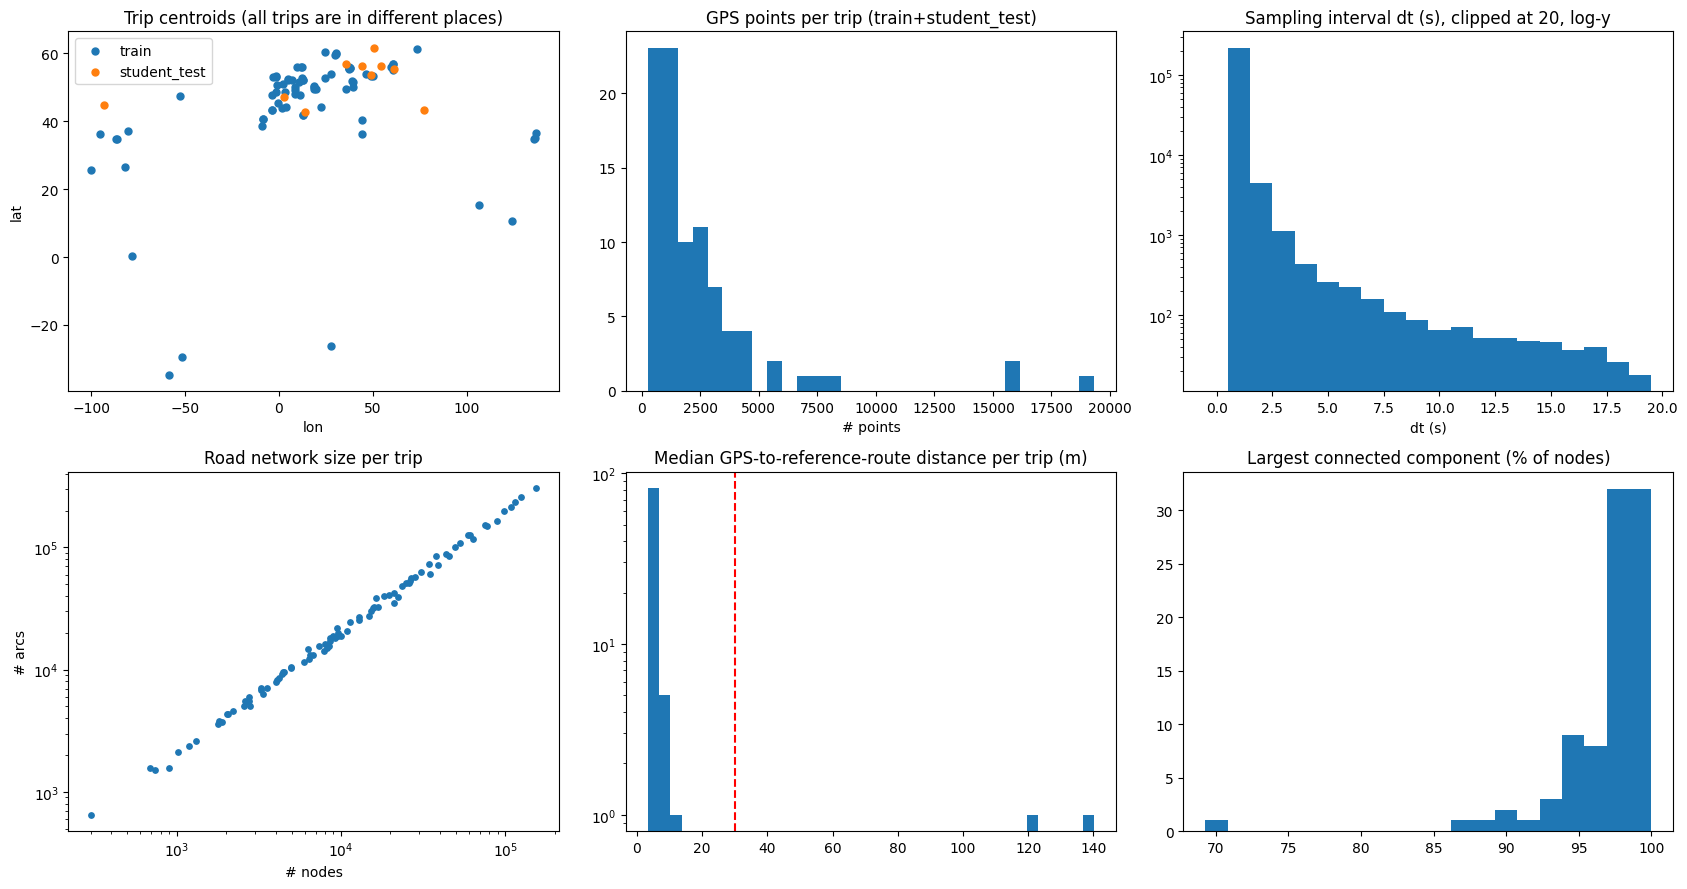

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for part, c in zip(PARTS, ["tab:blue", "tab:orange"]):
    g = gps[gps.partition == part]
    ax[0, 0].scatter(g.lon_mean, g.lat_mean, c=c, label=part, s=25)
ax[0, 0].set_title("Trip centroids (all trips are in different places)"); ax[0, 0].set_xlabel("lon"); ax[0, 0].set_ylabel("lat"); ax[0, 0].legend()
ax[0, 1].hist(gps.n_gps, bins=30); ax[0, 1].set_title("GPS points per trip (train+student_test)"); ax[0, 1].set_xlabel("# points")
alldt = np.concatenate([np.diff(load_trip(d, t, with_route=False)["track"].t.to_numpy()) for d in PARTS.values() for t in list_trips(d)])
ax[0, 2].hist(np.clip(alldt, 0, 20), bins=np.arange(0, 21) - 0.5, log=True); ax[0, 2].set_title("Sampling interval dt (s), clipped at 20, log-y"); ax[0, 2].set_xlabel("dt (s)")
ax[1, 0].scatter(net.n_nodes, net.n_arcs, s=15); ax[1, 0].set_xscale("log"); ax[1, 0].set_yscale("log")
ax[1, 0].set_title("Road network size per trip"); ax[1, 0].set_xlabel("# nodes"); ax[1, 0].set_ylabel("# arcs")
ax[1, 1].hist(q.resid_median_m, bins=40, log=True); ax[1, 1].set_title("Median GPS-to-reference-route distance per trip (m)"); ax[1, 1].axvline(QUALITY_MAX_MEDIAN_RESID_M, c="r", ls="--")
ax[1, 2].hist(net.largest_comp_pct, bins=20); ax[1, 2].set_title("Largest connected component (% of nodes)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "eda_overview.png"), dpi=130); plt.show()

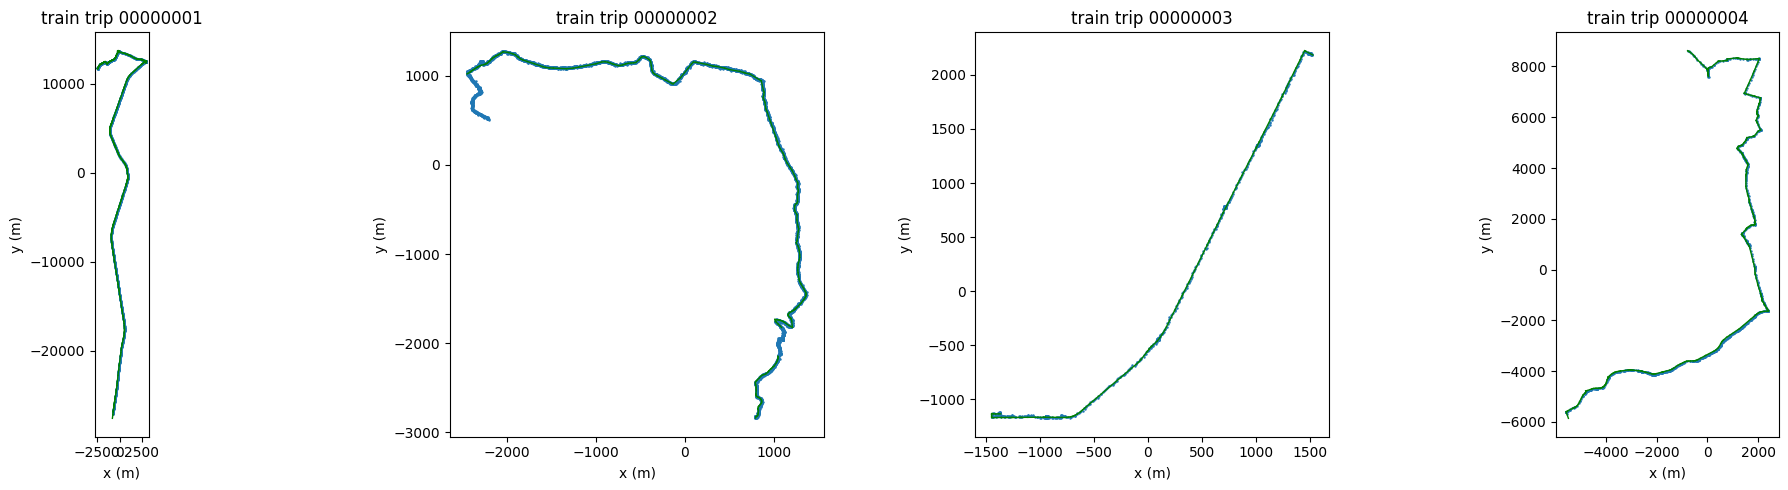

In [9]:
# GPS vs reference route in local metres for 4 training trips (pick any - change the list)
show = list_trips(TRAIN_DIR)[:4]
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for a, tid in zip(axs, show):
    trip = load_trip(TRAIN_DIR, tid); geo = TripGeometry(trip); rt = trip["route"]
    a.plot(geo.gx, geo.gy, ".", ms=1.5, c="tab:blue", label="GPS")
    for i in rt:
        a.plot([geo.ax[i], geo.bx[i]], [geo.ay[i], geo.by[i]], c="green", lw=1)
    a.set_title(f"train trip {tid}"); a.set_aspect("equal"); a.set_xlabel("x (m)"); a.set_ylabel("y (m)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "eda_gps_vs_route.png"), dpi=130); plt.show()

## 7. Folium map: raw GPS + road network + reference route (train partition)

In [10]:
TRIP_FOR_MAP = list_trips(TRAIN_DIR)[0]          # <-- change to any trip id
trip = load_trip(TRAIN_DIR, TRIP_FOR_MAP); geo = TripGeometry(trip)
m = make_trip_map(trip, geo, {"Reference route (.route)": dict(arcs=list(trip["route"]), color="green", weight=5)},
                  os.path.join(MAP_DIR, "eda_trip_map.html"))
m

## 8. Data-quality log - **Your analysis**
Fill this in with what YOU observed in the tables above. Things to check and explain:
- missing / invalid values (the tables print the counts), timestamp ordering and duplicates
- how many trips are ~1 Hz and which ones have big gaps (and what that means for the HMM)
- the road network is directed: how many arcs have a reverse twin (parallel carriageway / opposite direction problem)
- connected components and isolated nodes
- is `.route` a connected arc sequence? Which trips have a reference route that doesn't fit their GPS (section 5) and what you decided
- why Euclidean distance in degrees is wrong and which projection you used and why

---
# ===== 02_features_and_labels.ipynb =====

# 02 - Labels, candidate generation & feature engineering
**Partitions used:** `train` for all design decisions (radius study, filtering), `student_test` is only transformed with the *same* fixed settings.

**Problem formulation:** for every GPS point we generate **candidate road arcs** within `RADIUS_M`. A classifier scores each (point, candidate) pair: *is this the reference arc for this point?* The HMM later picks a coherent sequence of candidates.

**Inputs:** `artifacts/trip_quality.csv` (from notebook 01) and the settings in `src/config.py`.
**Outputs:** `artifacts/data/train_candidates.parquet`, `artifacts/data/student_test_candidates.parquet`, `artifacts/pipeline_config.json`.

In [11]:
import sys, os, json, time, warnings
sys.path.append(os.path.abspath("../src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import *

from pathsnap_core import *
import matplotlib
quality = pd.read_csv(QUALITY_CSV, dtype={"trip_id": str})
bad = set(quality.loc[quality.exclude_from_training, "trip_id"])
print("trips excluded from TRAINING (reference route does not fit GPS):", sorted(bad))

trips excluded from TRAINING (reference route does not fit GPS): ['00000033', '00000054']


## 1. Choosing the candidate radius (train trips only)
Trade-off: a bigger radius lowers the *candidate miss rate* but adds more wrong candidates per point.

,miss_rate,no_candidate_rate,avg_cands
radius,,,
20,0.027201,0.016614,4.505605
30,0.010349,0.004108,6.235834
40,0.006191,0.001940,7.791410
50,0.004781,0.001118,9.099975
75,0.003528,0.000431,11.497896
100,0.003098,0.000057,12.779045


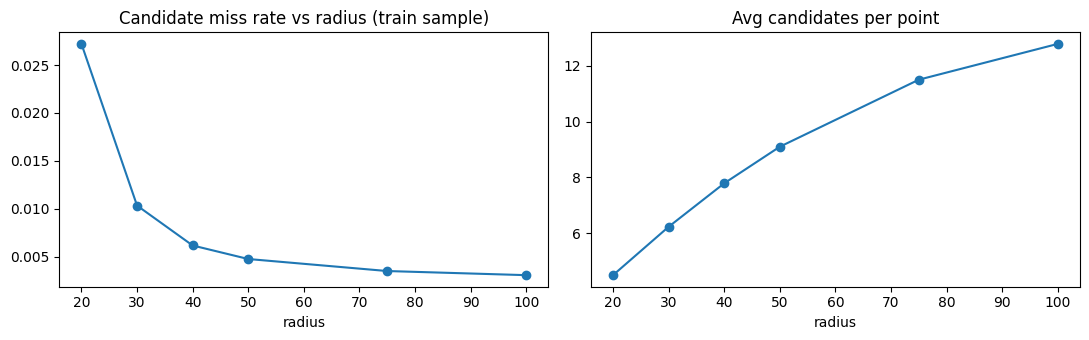

In [12]:
rng = np.random.default_rng(SEED)
good_train = [t for t in list_trips(TRAIN_DIR) if t not in bad]
sample = list(rng.choice(good_train, 15, replace=False))
rows = []
for tid in sample:
    trip = load_trip(TRAIN_DIR, tid); geo = TripGeometry(trip)
    path, _ = align_points_to_route(geo, trip["route"], SKIP_PEN); ref_arc = trip["route"][path]
    for R in (20, 30, 40, 50, 75, 100):
        c = generate_candidates(geo, R, 15)
        hit = np.zeros(geo.n_gps, bool); m = c.arc.to_numpy() == ref_arc[c.pt.to_numpy()]; hit[c.pt.to_numpy()[m]] = True
        has = np.zeros(geo.n_gps, bool); has[c.pt.unique()] = True
        rows.append(dict(trip_id=tid, radius=R, miss_rate=1 - hit.mean(), no_candidate_rate=1 - has.mean(), avg_cands=len(c) / geo.n_gps))
rad = pd.DataFrame(rows).groupby("radius").mean(numeric_only=True)
rad.to_csv(os.path.join(OUTPUTS, "eda", "radius_study.csv")); display(rad)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
rad.miss_rate.plot(ax=ax[0], marker="o", title="Candidate miss rate vs radius (train sample)"); rad.avg_cands.plot(ax=ax[1], marker="o", title="Avg candidates per point")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "radius_study.png"), dpi=130); plt.show()

Pick `RADIUS_M` in `src/config.py` using this table and **justify the choice in your report** (default 50 m).

## 2. Build candidate tables for all trips (train + student_test)

In [13]:
def build_partition(directory, label):
    out = []; t0 = time.time()
    for k, tid in enumerate(list_trips(directory)):
        trip = load_trip(directory, tid)
        geo, cand, ref_arc = trip_candidate_table(trip, RADIUS_M, K_MAX, True, SKIP_PEN)
        cand["n_gps"] = geo.n_gps
        out.append(cand)
        if k % 10 == 0: print(f"  {label}: {k+1}/{len(list_trips(directory))}  ({time.time()-t0:.0f}s)")
    df = pd.concat(out, ignore_index=True)
    for c in df.columns:                       # shrink memory
        if df[c].dtype == "float64": df[c] = df[c].astype("float32")
    return df

train_all = build_partition(TRAIN_DIR, "train")
test_all = build_partition(TEST_DIR, "student_test")
train_all.to_parquet(TRAIN_TABLE); test_all.to_parquet(TEST_TABLE)
print(train_all.shape, test_all.shape)

  train: 1/80  (0s)
  train: 11/80  (3s)
  train: 21/80  (5s)
  train: 31/80  (8s)
  train: 41/80  (11s)
  train: 51/80  (15s)
  train: 61/80  (16s)
  train: 71/80  (21s)
  student_test: 1/10  (0s)
(1474556, 30) (164349, 30)


## 3. Sanity checks on the candidate tables

In [14]:
def partition_report(df, name, exclude=()):
    d = df[~df.trip_id.isin(exclude)]
    pts = d.groupby(["trip_id", "pt"]).label.max()
    n_total_pts = d.drop_duplicates("trip_id").n_gps.sum()
    return dict(partition=name, rows=len(d), points_with_candidates=len(pts), total_gps_points=int(n_total_pts),
                no_candidate_rate=1 - len(pts) / n_total_pts, candidate_miss_rate_among_points_with_cands=1 - pts.mean(),
                positive_rate_rows=d.label.mean(), avg_cands_per_point=len(d) / len(pts))
rep = pd.DataFrame([partition_report(train_all, "train (all)"), partition_report(train_all, "train (quality-filtered)", bad),
                    partition_report(test_all, "student_test")])
rep.to_csv(os.path.join(OUTPUTS, "eda", "candidate_table_report.csv"), index=False); display(rep.T)

,0,1,2
partition,train (all),train (quality-filtered),student_test
rows,1474556,1400608,164349
points_with_candidates,190187,181594,19160
total_gps_points,208417,183260,19160
no_candidate_rate,0.087469,0.009091,0.0
candidate_miss_rate_among_points_with_cands,0.031285,0.006113,0.002035
positive_rate_rows,0.124944,0.128861,0.116344
avg_cands_per_point,7.75319,7.712854,8.577714


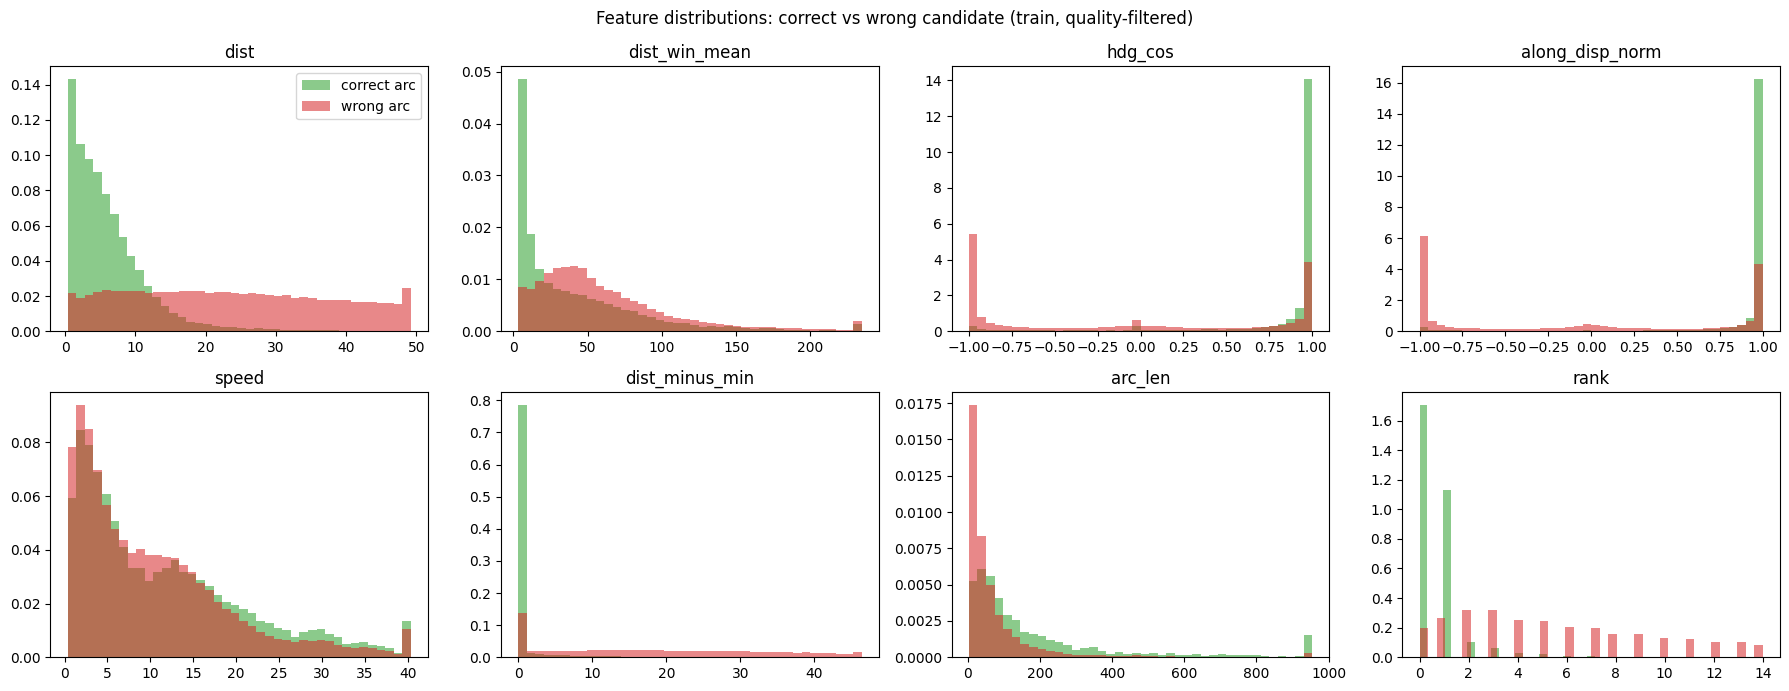

In [15]:
good = train_all[~train_all.trip_id.isin(bad)]
s = good.sample(200000, random_state=SEED)
fig, axs = plt.subplots(2, 4, figsize=(18, 7)); axs = axs.ravel()
for a, f in zip(axs, ["dist", "dist_win_mean", "hdg_cos", "along_disp_norm", "speed", "dist_minus_min", "arc_len", "rank"]):
    lo, hi = s[f].quantile(0.01), s[f].quantile(0.99)
    for lab, c in [(1, "tab:green"), (0, "tab:red")]:
        a.hist(s[s.label == lab][f].clip(lo, hi), bins=40, alpha=0.55, density=True, color=c, label="correct arc" if lab else "wrong arc")
    a.set_title(f); 
axs[0].legend(); plt.suptitle("Feature distributions: correct vs wrong candidate (train, quality-filtered)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "feature_distributions.png"), dpi=130); plt.show()

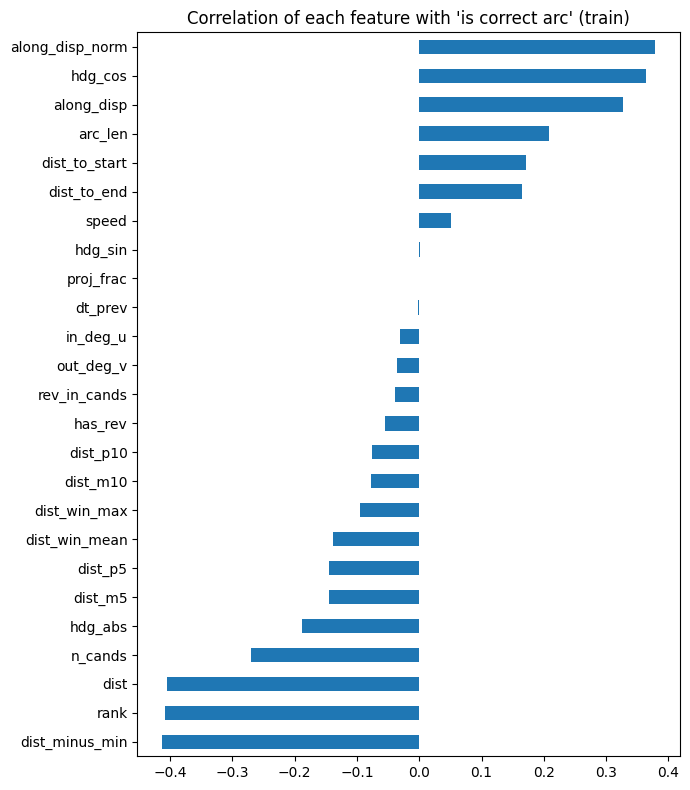

In [16]:
corr = good[FEATURES + ["label"]].sample(200000, random_state=SEED).corr()["label"].drop("label").sort_values()
corr.to_csv(os.path.join(OUTPUTS, "eda", "feature_label_correlation.csv"))
corr.plot.barh(figsize=(7, 8), title="Correlation of each feature with 'is correct arc' (train)"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "feature_label_corr.png"), dpi=130); plt.show()

## 4. Save the pipeline configuration (read by the API)
**Your analysis (report 2.2):** explain each feature group - distance (how close), window distances (does the arc fit the *neighbouring* points too), heading/along-displacement (direction of travel, separates an arc from its reverse twin), speed/dt, topology (degrees, reverse twin), arc geometry.

In [17]:
cfg = dict(radius_m=RADIUS_M, k_max=K_MAX, skip_pen=SKIP_PEN, features=FEATURES, stride=STRIDE,
           excluded_training_trips=sorted(bad), seed=SEED)
with open(os.path.join(ARTIFACTS, "pipeline_config.json"), "w") as f: json.dump(cfg, f, indent=2)
print(json.dumps(cfg, indent=2)[:600])

{
  "radius_m": 50.0,
  "k_max": 15,
  "skip_pen": 1.0,
  "features": [
    "dist",
    "dist_minus_min",
    "rank",
    "n_cands",
    "proj_frac",
    "arc_len",
    "speed",
    "dt_prev",
    "hdg_cos",
    "hdg_sin",
    "hdg_abs",
    "along_disp",
    "along_disp_norm",
    "dist_m10",
    "dist_m5",
    "dist_p5",
    "dist_p10",
    "dist_win_mean",
    "dist_win_max",
    "has_rev",
    "rev_in_cands",
    "out_deg_v",
    "in_deg_u",
    "dist_to_end",
    "dist_to_start"
  ],
  "stride": 6,
  "excluded_training_trips": [
    "00000033",
    "00000054"
  ],
  "seed": 42
}


---
# ===== 03_model_comparison.ipynb =====

# 03 - Model experimentation & comparison (7 models, 6 algorithm families)
**Partitions:** model fitting + group cross-validation on the **80 training trips** (minus quality-flagged ones); development comparison on the **10 student_test trips**. Evaluator data is never used.

**Task:** binary classification of candidate rows ("is this the reference arc for this GPS point?").
**Primary selection metric:** **observation-level top-1 accuracy** under trip-grouped CV - for each GPS point pick the highest-scoring candidate and compare with the reference arc. It is the metric closest to the route-matching objective; log loss is the secondary metric because the HMM consumes the *probabilities*.

**Input:** `artifacts/data/*.parquet` from notebook 02. **Outputs:** `outputs/model_comparison.csv`, figures in `outputs/figures/`.

In [18]:
import sys, os, json, time, warnings
sys.path.append(os.path.abspath("../src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import *

import joblib
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             confusion_matrix, roc_auc_score)
import lightgbm as lgb
from pathsnap_core import FEATURES, top1_accuracy

quality = pd.read_csv(QUALITY_CSV, dtype={"trip_id": str})
bad = set(quality.loc[quality.exclude_from_training, "trip_id"])
train = pd.read_parquet(TRAIN_TABLE); test = pd.read_parquet(TEST_TABLE)
train = train[~train.trip_id.isin(bad)].reset_index(drop=True)
trs = train[train.pt % STRIDE == 0].reset_index(drop=True)          # every STRIDE-th GPS point (all its candidates)
print("train rows (strided):", len(trs), "| trips:", trs.trip_id.nunique(), "| student_test rows:", len(test))

train rows (strided): 233459 | trips: 78 | student_test rows: 164349


## 1. Define the 7 models
Each entry: family, the configuration you must be able to explain, and which rows it is trained on.
KNN and the MLP are trained on a smaller random subset of points (`SLOW_ROWS`) because their cost grows quickly with data - state this in the report.

In [19]:
SLOW_ROWS = 60000
MODELS = {
 "LogisticRegression": dict(family="Linear", cfg="C=1.0, L2, StandardScaler, max_iter=500",
        make=lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500, random_state=SEED)), slow=False),
 "GaussianNB": dict(family="Probabilistic", cfg="var_smoothing=1e-9 (assumes independent Gaussian features)",
        make=lambda: GaussianNB(), slow=False),
 "KNN": dict(family="Instance-based", cfg="k=25, distance-weighted, StandardScaler, euclidean",
        make=lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1)), slow=True),
 "DecisionTree": dict(family="Tree-based", cfg="max_depth=12, min_samples_leaf=20",
        make=lambda: DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=SEED), slow=False),
 "RandomForest": dict(family="Ensemble (bagging)", cfg="n_estimators=150, max_depth=18, min_samples_leaf=5",
        make=lambda: RandomForestClassifier(n_estimators=150, max_depth=18, min_samples_leaf=5, n_jobs=-1, random_state=SEED), slow=False),
 "LightGBM": dict(family="Boosting", cfg=str({k: v for k, v in BASELINE_LGBM.items() if k not in ("verbose", "n_jobs", "random_state")}),
        make=lambda: lgb.LGBMClassifier(**BASELINE_LGBM), slow=False),
 "MLP": dict(family="Neural network", cfg="hidden=(64,32), relu, adam, early_stopping, StandardScaler",
        make=lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=60,
                                                                    random_state=SEED)), slow=True),
}
rng = np.random.default_rng(SEED)
slow_pts = trs[["trip_id", "pt"]].drop_duplicates().sample(frac=1, random_state=SEED)
n_pts = max(1, int(SLOW_ROWS / (len(trs) / len(slow_pts))))
slow_keys = set(map(tuple, slow_pts.head(n_pts).to_numpy()))
trs_slow = trs[[ (a, b) in slow_keys for a, b in zip(trs.trip_id, trs.pt)]].reset_index(drop=True)
print("slow-model training rows:", len(trs_slow))

slow-model training rows: 59842


## 2. Metric helpers

In [20]:
def evaluate(model, df, thr=0.5):
    t0 = time.time(); p = model.predict_proba(df[FEATURES])[:, 1]; inf = time.time() - t0
    y = df.label.to_numpy(); yh = (p >= thr).astype(int)
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return dict(accuracy=accuracy_score(y, yh), precision=precision_score(y, yh, zero_division=0),
                recall=recall_score(y, yh, zero_division=0), f1=f1_score(y, yh, zero_division=0),
                log_loss=log_loss(y, p), roc_auc=roc_auc_score(y, p), top1=top1_accuracy(df, p),
                infer_s_per_100k_rows=inf / len(df) * 1e5), p

def candidate_miss_rate(df):
    g = df.groupby(["trip_id", "pt"]).label.max(); return 1 - g.mean()

## 3. Trip-grouped cross-validation on training trips (no trip appears in both train and validation)

In [21]:
cv_rows = []; fold_detail = []
for name, M in MODELS.items():
    data = trs_slow if M["slow"] else trs
    gkf = GroupKFold(n_splits=N_SPLITS)
    for k, (a, b) in enumerate(gkf.split(data, groups=data.trip_id)):
        mdl = M["make"](); t0 = time.time(); mdl.fit(data.iloc[a][FEATURES], data.iloc[a].label); ft = time.time() - t0
        m, _ = evaluate(mdl, data.iloc[b]); m.update(model=name, fold=k, fit_s=ft); fold_detail.append(m)
    print(f"{name:20s} done  top1(CV) = {np.mean([r['top1'] for r in fold_detail if r['model']==name]):.4f}")
fd = pd.DataFrame(fold_detail); fd.to_csv(os.path.join(OUTPUTS, "cv_fold_results.csv"), index=False)
cv = fd.groupby("model").agg(cv_top1_mean=("top1", "mean"), cv_top1_std=("top1", "std"), cv_f1=("f1", "mean"),
                             cv_logloss=("log_loss", "mean"), cv_fit_s=("fit_s", "mean"))
cv

LogisticRegression   done  top1(CV) = 0.8802
GaussianNB           done  top1(CV) = 0.8529
KNN                  done  top1(CV) = 0.8607
DecisionTree         done  top1(CV) = 0.8795
RandomForest         done  top1(CV) = 0.8903
LightGBM             done  top1(CV) = 0.8903
MLP                  done  top1(CV) = 0.8810


,cv_top1_mean,cv_top1_std,cv_f1,cv_logloss,cv_fit_s
model,,,,,
DecisionTree,0.879539,0.023619,0.875244,0.121071,5.596984
GaussianNB,0.852880,0.014592,0.765397,0.395883,0.097946
KNN,0.860735,0.016518,0.830095,0.131564,0.023455
LightGBM,0.890327,0.028082,0.887213,0.075371,4.039953
LogisticRegression,0.880180,0.029639,0.851029,0.106320,1.362215
MLP,0.881015,0.012672,0.871618,0.088618,7.287041
RandomForest,0.890316,0.025083,0.888418,0.072879,45.117803


## 4. Final fit on all training trips and evaluation on the 10 student_test trips

In [22]:
fitted, rows, probs, hist = {}, [], {}, {}
for name, M in MODELS.items():
    data = trs_slow if M["slow"] else trs
    mdl = M["make"](); t0 = time.time(); mdl.fit(data[FEATURES], data.label); ft = time.time() - t0
    mt, pt_ = evaluate(mdl, test); mtr, _ = evaluate(mdl, data.sample(min(len(data), 60000), random_state=SEED))
    rows.append(dict(model=name, family=M["family"], config=M["cfg"], fit_s=ft, train_top1=mtr["top1"],
                     **{f"test_{k}": v for k, v in mt.items()}))
    fitted[name], probs[name] = mdl, pt_
res = pd.DataFrame(rows).merge(cv.reset_index(), on="model")
res["train_minus_test_top1"] = res.train_top1 - res.test_top1
res = res.sort_values("cv_top1_mean", ascending=False).reset_index(drop=True)
res.to_csv(os.path.join(OUTPUTS, "model_comparison.csv"), index=False)
print("Candidate miss rate (student_test, same for every model):", round(candidate_miss_rate(test), 4))
res[["model", "family", "cv_top1_mean", "cv_top1_std", "test_top1", "test_precision", "test_recall", "test_f1", "test_log_loss",
     "test_roc_auc", "train_top1", "train_minus_test_top1", "fit_s", "test_infer_s_per_100k_rows"]].round(4)

Candidate miss rate (student_test, same for every model): 0.002


,model,family,cv_top1_mean,cv_top1_std,test_top1,test_precision,test_recall,test_f1,test_log_loss,test_roc_auc,train_top1,train_minus_test_top1,fit_s,test_infer_s_per_100k_rows
0,LightGBM,Boosting,0.8903,0.0281,0.8980,0.9051,0.8782,0.8915,0.0636,0.9934,0.3205,-0.5775,5.4516,0.6399
1,RandomForest,Ensemble (bagging),0.8903,0.0251,0.8846,0.9028,0.8582,0.8799,0.0671,0.9927,0.3206,-0.5640,72.7609,0.5009
2,MLP,Neural network,0.8810,0.0127,0.8783,0.8519,0.8792,0.8653,0.0810,0.9900,0.8895,0.0112,6.3600,0.0999
3,LogisticRegression,Linear,0.8802,0.0296,0.8700,0.8466,0.8418,0.8442,0.0935,0.9862,0.3100,-0.5600,2.0900,0.0550
4,DecisionTree,Tree-based,0.8795,0.0236,0.8767,0.8632,0.8668,0.8650,0.0996,0.9782,0.3158,-0.5609,8.8274,0.0163
5,KNN,Instance-based,0.8607,0.0165,0.8596,0.8587,0.8046,0.8307,0.1152,0.9796,0.9923,0.1327,0.0265,18.7569
6,GaussianNB,Probabilistic,0.8529,0.0146,0.8205,0.6504,0.8659,0.7428,0.4215,0.9612,0.3048,-0.5156,0.1355,0.0589


## 5. Required visualisations (all from the real results above)

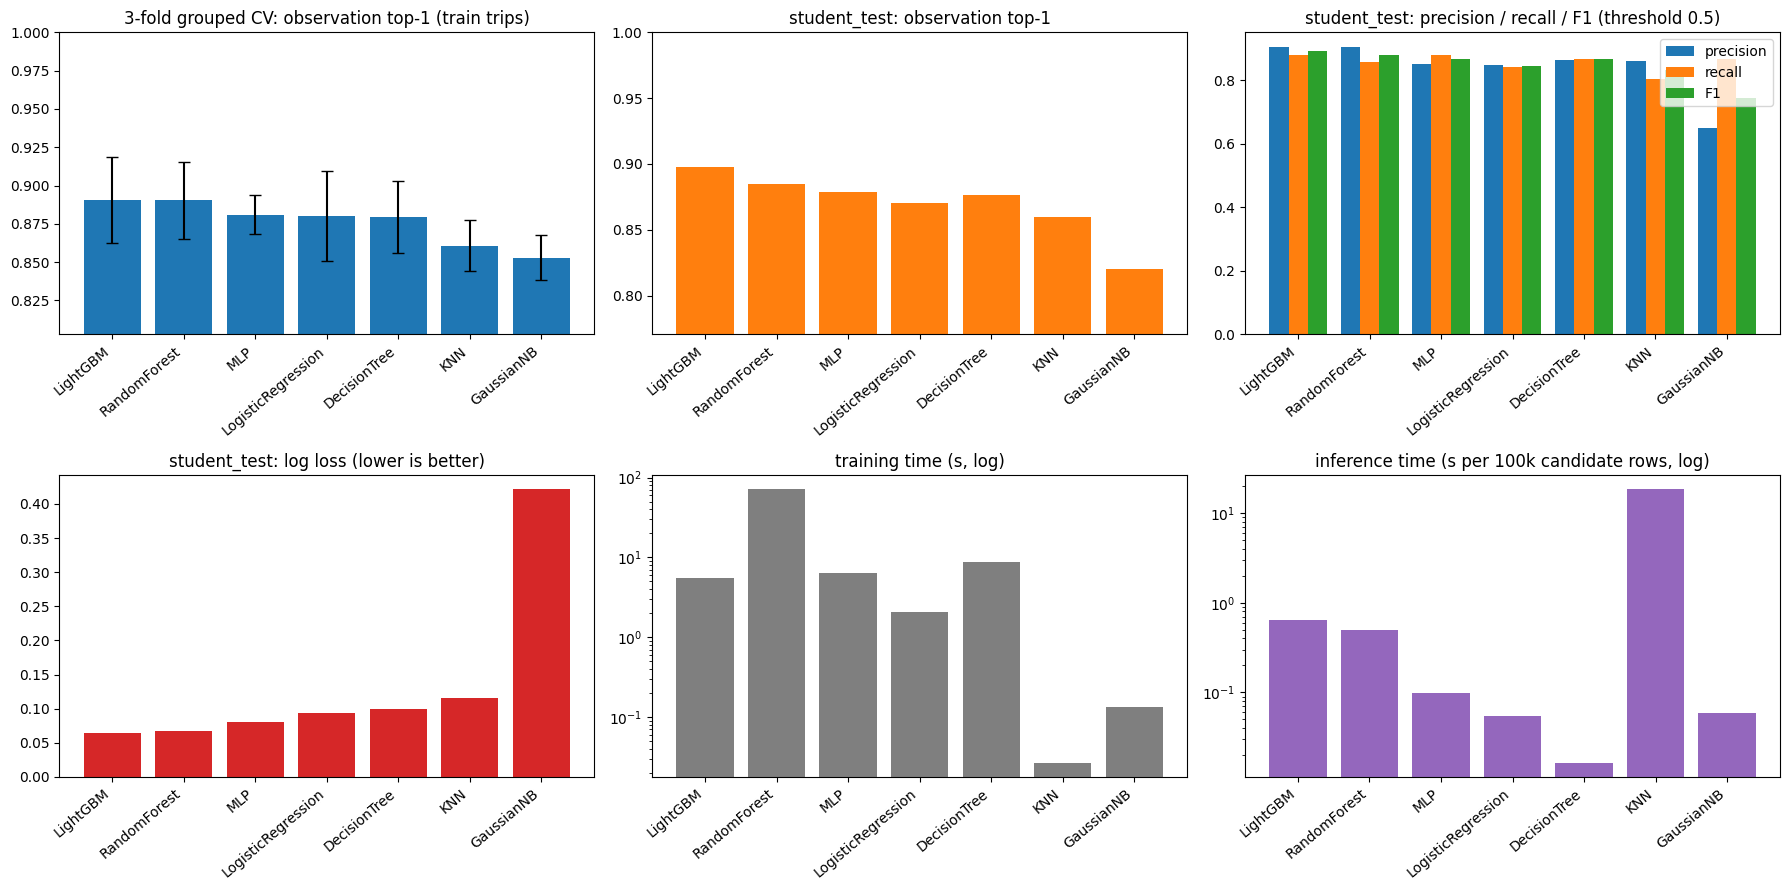

In [23]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9)); order = res.model.tolist(); x = np.arange(len(order))
ax[0, 0].bar(x, res.cv_top1_mean, yerr=res.cv_top1_std, capsize=4); ax[0, 0].set_title(f"{N_SPLITS}-fold grouped CV: observation top-1 (train trips)")
ax[0, 1].bar(x, res.test_top1, color="tab:orange"); ax[0, 1].set_title("student_test: observation top-1")
w = 0.27
ax[0, 2].bar(x - w, res.test_precision, w, label="precision"); ax[0, 2].bar(x, res.test_recall, w, label="recall"); ax[0, 2].bar(x + w, res.test_f1, w, label="F1")
ax[0, 2].legend(); ax[0, 2].set_title("student_test: precision / recall / F1 (threshold 0.5)")
ax[1, 0].bar(x, res.test_log_loss, color="tab:red"); ax[1, 0].set_title("student_test: log loss (lower is better)")
ax[1, 1].bar(x, res.fit_s, color="tab:gray"); ax[1, 1].set_yscale("log"); ax[1, 1].set_title("training time (s, log)")
ax[1, 2].bar(x, res.test_infer_s_per_100k_rows, color="tab:purple"); ax[1, 2].set_yscale("log"); ax[1, 2].set_title("inference time (s per 100k candidate rows, log)")
for a in ax.ravel(): a.set_xticks(x); a.set_xticklabels(order, rotation=40, ha="right")
ax[0, 0].set_ylim(max(0, res.cv_top1_mean.min() - 0.05), 1); ax[0, 1].set_ylim(max(0, res.test_top1.min() - 0.05), 1)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "model_comparison.png"), dpi=130); plt.show()

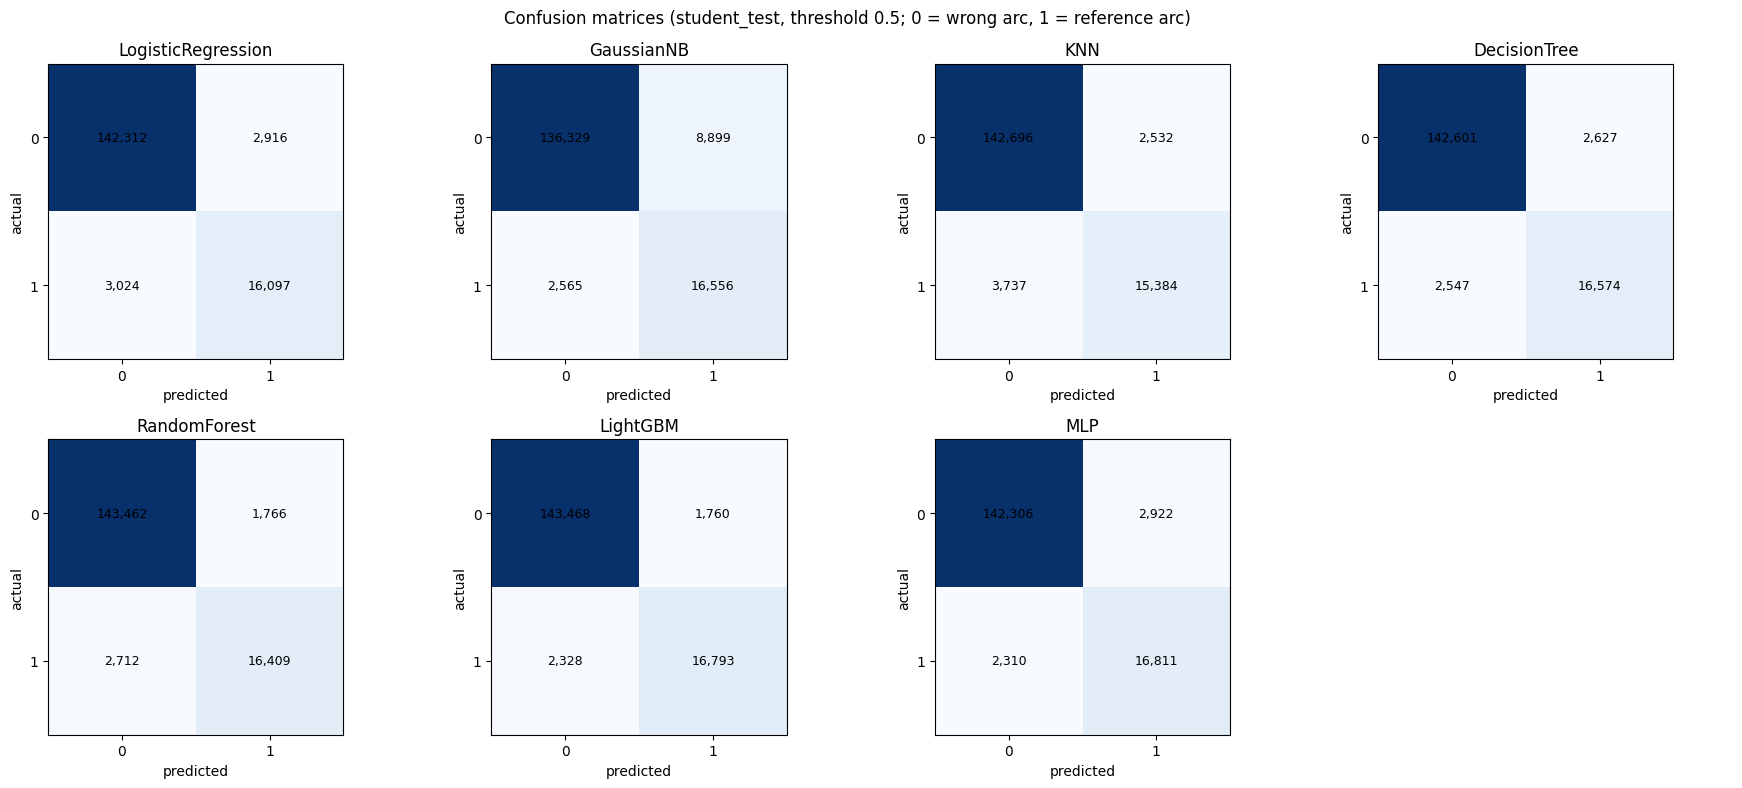

In [24]:
fig, axs = plt.subplots(2, 4, figsize=(18, 8)); axs = axs.ravel()
for a, name in zip(axs, MODELS):
    cm = confusion_matrix(test.label, (probs[name] >= 0.5).astype(int))
    a.imshow(cm, cmap="Blues"); a.set_title(name)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black", fontsize=9)
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xlabel("predicted"); a.set_ylabel("actual")
axs[-1].axis("off"); plt.suptitle("Confusion matrices (student_test, threshold 0.5; 0 = wrong arc, 1 = reference arc)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "confusion_matrices.png"), dpi=130); plt.show()

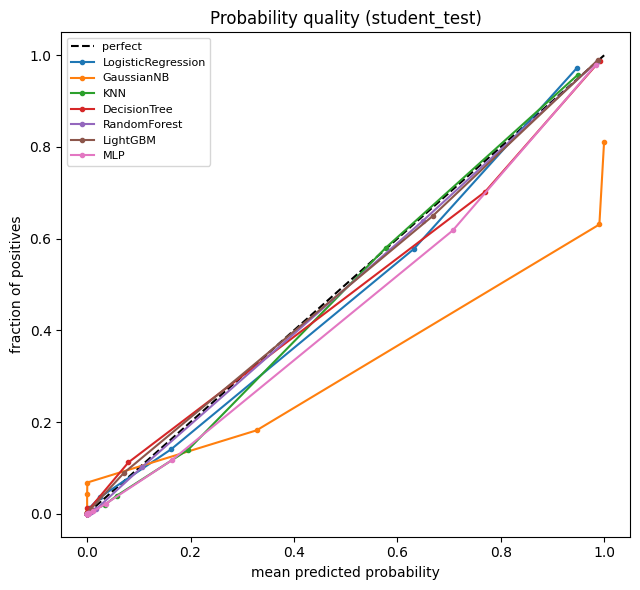

In [25]:
plt.figure(figsize=(6.5, 6)); plt.plot([0, 1], [0, 1], "k--", label="perfect")
for name in MODELS:
    fr, mp = calibration_curve(test.label, probs[name], n_bins=15, strategy="quantile"); plt.plot(mp, fr, marker="o", ms=3, label=name)
plt.xlabel("mean predicted probability"); plt.ylabel("fraction of positives"); plt.title("Probability quality (student_test)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "calibration.png"), dpi=130); plt.show()

### Training histories (only for models that really have them - do NOT fake curves for the others)

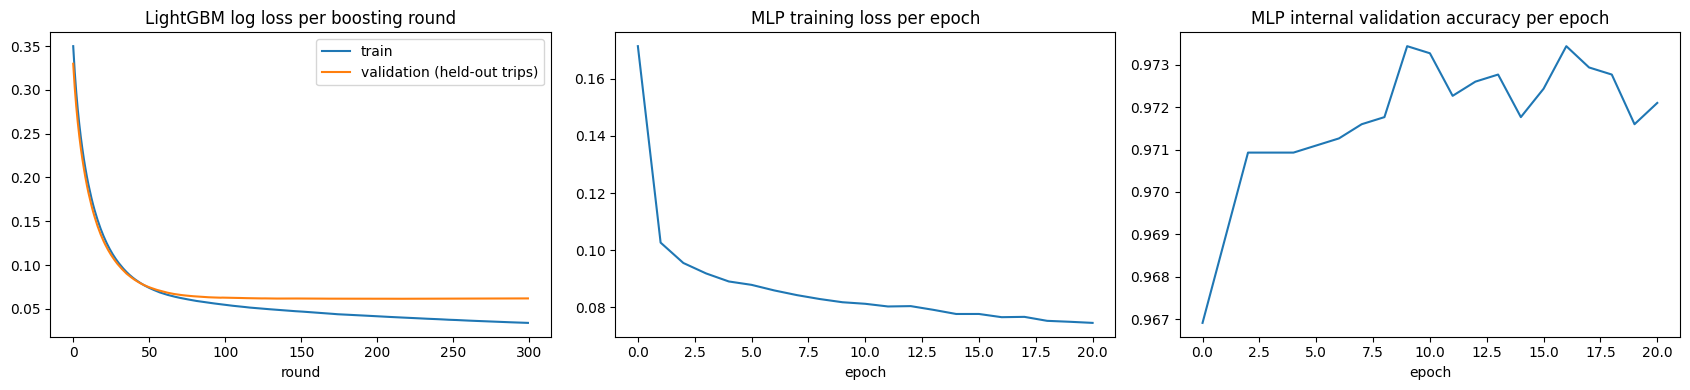

In [26]:
# LightGBM: per-iteration loss on a held-out set of TRAINING trips
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
a, b = next(gss.split(trs, groups=trs.trip_id))
ev = {}
g = lgb.LGBMClassifier(**BASELINE_LGBM).fit(trs.iloc[a][FEATURES], trs.iloc[a].label,
        eval_set=[(trs.iloc[a][FEATURES], trs.iloc[a].label), (trs.iloc[b][FEATURES], trs.iloc[b].label)],
        eval_names=["train", "validation"], eval_metric="binary_logloss", callbacks=[lgb.record_evaluation(ev)])
mlp = fitted["MLP"].steps[-1][1]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(ev["train"]["binary_logloss"], label="train"); ax[0].plot(ev["validation"]["binary_logloss"], label="validation (held-out trips)")
ax[0].set_title("LightGBM log loss per boosting round"); ax[0].set_xlabel("round"); ax[0].legend()
ax[1].plot(mlp.loss_curve_); ax[1].set_title("MLP training loss per epoch"); ax[1].set_xlabel("epoch")
ax[2].plot(mlp.validation_scores_); ax[2].set_title("MLP internal validation accuracy per epoch"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "training_histories.png"), dpi=130); plt.show()

## 6. Model selection
The cell prints the ranking by the primary metric (CV top-1). **Your analysis:** decide using CV mean *and* its std (stability across folds), student_test top-1, log loss (probability quality for the HMM), train-vs-test gap (overfitting) and inference time. Then answer the 9 compulsory questions for EVERY model in the report, using the numbers above.

In [27]:
best = res.iloc[0]
print("Best by CV top-1:", best.model, f"(CV {best.cv_top1_mean:.4f} +- {best.cv_top1_std:.4f}, student_test top-1 {best.test_top1:.4f}, log loss {best.test_log_loss:.4f})")
res[["model", "cv_top1_mean", "cv_top1_std", "test_top1", "test_log_loss", "train_minus_test_top1", "fit_s"]].round(4)

Best by CV top-1: LightGBM (CV 0.8903 +- 0.0281, student_test top-1 0.8980, log loss 0.0636)


,model,cv_top1_mean,cv_top1_std,test_top1,test_log_loss,train_minus_test_top1,fit_s
0,LightGBM,0.8903,0.0281,0.8980,0.0636,-0.5775,5.4516
1,RandomForest,0.8903,0.0251,0.8846,0.0671,-0.5640,72.7609
2,MLP,0.8810,0.0127,0.8783,0.0810,0.0112,6.3600
3,LogisticRegression,0.8802,0.0296,0.8700,0.0935,-0.5600,2.0900
4,DecisionTree,0.8795,0.0236,0.8767,0.0996,-0.5609,8.8274
5,KNN,0.8607,0.0165,0.8596,0.1152,0.1327,0.0265
6,GaussianNB,0.8529,0.0146,0.8205,0.4215,-0.5156,0.1355


---
# ===== 04_bayesian_optimisation.ipynb =====

# 04 - Bayesian hyperparameter optimisation (Optuna / TPE)
**Partitions:** group-aware CV on the **training trips**; tuned-vs-untuned comparison on **student_test**. Evaluator data is never used.

**Model tuned:** LightGBM (the model that ranked best in notebook 03 - if your ranking differs, tune YOUR winner instead and justify it).
**Objective maximised:** mean observation-level top-1 accuracy over trip-grouped CV folds (the same primary metric as notebook 03).
**Bayesian strategy:** Tree-structured Parzen Estimator (`optuna.samplers.TPESampler`).

**Inputs:** parquet tables from notebook 02. **Outputs:** `artifacts/model_lgbm_tuned.joblib`, `artifacts/best_params.json`, `outputs/bo_trials.csv`, figures.

In [28]:
import sys, os, json, time, warnings
sys.path.append(os.path.abspath("../src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import *

import joblib, optuna
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, roc_auc_score
import lightgbm as lgb
from pathsnap_core import FEATURES, top1_accuracy
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 30            # <-- number of Bayesian trials (30-60 is a reasonable range)
N_SPLITS_BO = 3          # <-- grouped CV folds inside every trial

quality = pd.read_csv(QUALITY_CSV, dtype={"trip_id": str})
bad = set(quality.loc[quality.exclude_from_training, "trip_id"])
train = pd.read_parquet(TRAIN_TABLE); test = pd.read_parquet(TEST_TABLE)
train = train[~train.trip_id.isin(bad)].reset_index(drop=True)
trs = train[train.pt % STRIDE == 0].reset_index(drop=True)
print(len(trs), "rows;", trs.trip_id.nunique(), "trips")

233459 rows; 78 trips


## 1. Search space (justify every range in the report)

In [29]:
def suggest(trial):
    return dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),          # more rounds = more capacity
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),      # shrinkage, interacts with n_estimators
        num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),                # tree complexity
        max_depth=trial.suggest_int("max_depth", 4, 16),                              # hard cap against overfitting
        min_child_samples=trial.suggest_int("min_child_samples", 10, 200, log=True),  # min rows per leaf (smoothing)
        subsample=trial.suggest_float("subsample", 0.5, 1.0),                         # row sampling
        subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),           # feature sampling
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),             # L2
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),               # L1
    )

gkf = GroupKFold(n_splits=N_SPLITS_BO)
folds = list(gkf.split(trs, groups=trs.trip_id))
def objective(trial):
    params = suggest(trial); scores = []; t0 = time.time()
    for a, b in folds:
        m = lgb.LGBMClassifier(**params, random_state=SEED, verbose=-1, n_jobs=-1).fit(trs.iloc[a][FEATURES], trs.iloc[a].label)
        p = m.predict_proba(trs.iloc[b][FEATURES])[:, 1]
        scores.append(top1_accuracy(trs.iloc[b], p))
    trial.set_user_attr("cv_std", float(np.std(scores))); trial.set_user_attr("secs", time.time() - t0)
    return float(np.mean(scores))

## 2. Run the Bayesian search

In [30]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8),
                            study_name="lgbm_top1")
t0 = time.time()
def cb(study, trial): print(f"trial {trial.number:3d}  top1={trial.value:.4f}  best={study.best_value:.4f}  ({trial.user_attrs['secs']:.0f}s)")
study.optimize(objective, n_trials=N_TRIALS, callbacks=[cb])
bo_seconds = time.time() - t0
trials = study.trials_dataframe(); trials.to_csv(os.path.join(OUTPUTS, "bo_trials.csv"), index=False)
best = study.best_params; best["subsample_freq"] = 1
with open(os.path.join(ARTIFACTS, "best_params.json"), "w") as f: json.dump(best, f, indent=2)
print("Best CV top-1:", round(study.best_value, 4), "| total BO time: %.0f s" % bo_seconds); print(best)

trial   0  top1=0.8879  best=0.8879  (19s)
trial   1  top1=0.8913  best=0.8913  (39s)
trial   2  top1=0.8915  best=0.8915  (11s)
trial   3  top1=0.8894  best=0.8915  (12s)
trial   4  top1=0.8906  best=0.8915  (13s)
trial   5  top1=0.8906  best=0.8915  (26s)
trial   6  top1=0.8887  best=0.8915  (14s)
trial   7  top1=0.8904  best=0.8915  (10s)
trial   8  top1=0.8906  best=0.8915  (15s)
trial   9  top1=0.8893  best=0.8915  (7s)
trial  10  top1=0.8913  best=0.8915  (11s)
trial  11  top1=0.8911  best=0.8915  (32s)
trial  12  top1=0.8913  best=0.8915  (28s)
trial  13  top1=0.8904  best=0.8915  (8s)
trial  14  top1=0.8919  best=0.8919  (17s)
trial  15  top1=0.8913  best=0.8919  (13s)
trial  16  top1=0.8919  best=0.8919  (13s)
trial  17  top1=0.8907  best=0.8919  (10s)
trial  18  top1=0.8916  best=0.8919  (10s)
trial  19  top1=0.8905  best=0.8919  (20s)
trial  20  top1=0.8913  best=0.8919  (20s)
trial  21  top1=0.8912  best=0.8919  (17s)
trial  22  top1=0.8911  best=0.8919  (13s)
trial  23  to

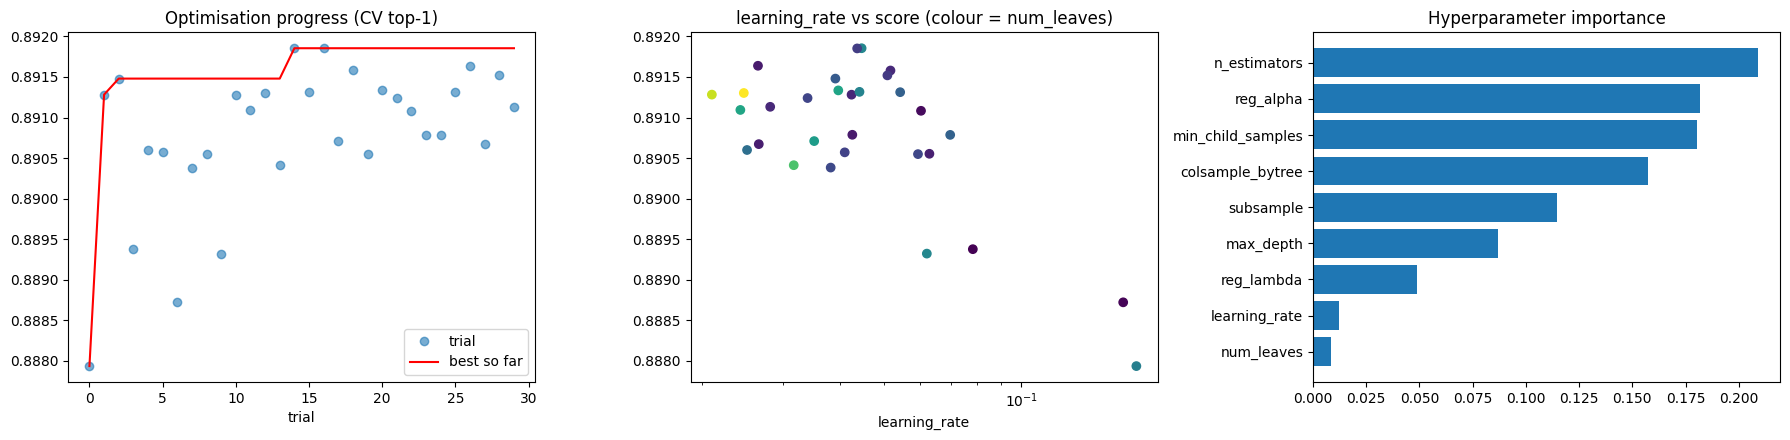

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_cv_std,user_attrs_secs,system_attrs_tpe:relative_params:0,state
14,14,0.891854,2026-11-17 13:43:48.150696,2026-11-17 13:44:05.057254,0 days 00:00:16.906558,0.671079,0.044642,6,31,400,126,0.042103,0.094946,0.687374,0.021579,16.894938,"{""colsample_bytree"": 0.6710791313077951, ""lear...",COMPLETE
16,16,0.891851,2026-11-17 13:44:18.314790,2026-11-17 13:44:31.001369,0 days 00:00:12.686579,0.711340,0.043650,4,29,400,59,0.013033,1.169560,0.705398,0.021218,12.675024,"{""colsample_bytree"": 0.7113400520706318, ""lear...",COMPLETE
26,26,0.891638,2026-11-17 13:46:39.046069,2026-11-17 13:46:52.887021,0 days 00:00:13.840952,0.640612,0.026464,6,24,350,34,0.022731,0.273289,0.749030,0.022038,13.826943,"{""colsample_bytree"": 0.640611634285543, ""learn...",COMPLETE
18,18,0.891579,2026-11-17 13:44:41.087844,2026-11-17 13:44:51.284701,0 days 00:00:10.196857,0.747782,0.051638,4,35,300,45,0.004675,0.183232,0.692285,0.021710,10.183758,"{""colsample_bytree"": 0.7477816176854248, ""lear...",COMPLETE
28,28,0.891519,2026-11-17 13:47:05.820080,2026-11-17 13:47:20.450703,0 days 00:00:14.630623,0.624627,0.050842,6,23,350,57,0.045968,1.018404,0.736960,0.022119,14.617719,"{""colsample_bytree"": 0.6246265886369777, ""lear...",COMPLETE
2,2,0.891479,2026-11-17 13:40:41.014472,2026-11-17 13:40:52.287718,0 days 00:00:11.273246,0.728035,0.039107,5,23,300,84,0.006291,1.382623,0.683181,0.022233,11.270799,NaN,COMPLETE
20,20,0.891334,2026-11-17 13:45:11.726600,2026-11-17 13:45:31.298881,0 days 00:00:19.572281,0.646860,0.039686,9,17,300,155,0.011598,0.052694,0.772331,0.020853,19.560069,"{""colsample_bytree"": 0.6468598416995276, ""lear...",COMPLETE
15,15,0.891316,2026-11-17 13:44:05.057802,2026-11-17 13:44:18.314282,0 days 00:00:13.256480,0.774594,0.044166,7,44,250,123,0.216022,0.318872,0.774914,0.022265,13.245166,"{""colsample_bytree"": 0.7745942890678559, ""lear...",COMPLETE


In [31]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
v = trials.value.to_numpy(); ax[0].plot(v, "o", alpha=0.6, label="trial"); ax[0].plot(np.maximum.accumulate(v), "r-", label="best so far")
ax[0].set_title("Optimisation progress (CV top-1)"); ax[0].set_xlabel("trial"); ax[0].legend()
ax[1].scatter(trials.params_learning_rate, v, c=trials.params_num_leaves, cmap="viridis"); ax[1].set_xscale("log")
ax[1].set_title("learning_rate vs score (colour = num_leaves)"); ax[1].set_xlabel("learning_rate")
imp = optuna.importance.get_param_importances(study); ax[2].barh(list(imp.keys())[::-1], list(imp.values())[::-1]); ax[2].set_title("Hyperparameter importance")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "bo_progress.png"), dpi=130); plt.show()
trials.sort_values("value", ascending=False).head(8)

## 3. Refit tuned model and compare with the untuned baseline on student_test

In [32]:
def evaluate(model, df, thr=0.5):
    t0 = time.time(); p = np.clip(model.predict_proba(df[FEATURES])[:, 1], 1e-6, 1 - 1e-6); inf = time.time() - t0
    y = df.label.to_numpy(); yh = (p >= thr).astype(int)
    return dict(top1=top1_accuracy(df, p), accuracy=accuracy_score(y, yh), precision=precision_score(y, yh), recall=recall_score(y, yh),
                f1=f1_score(y, yh), log_loss=log_loss(y, p), roc_auc=roc_auc_score(y, p), infer_s_per_100k=inf / len(df) * 1e5)

base = lgb.LGBMClassifier(**BASELINE_LGBM); t0 = time.time(); base.fit(trs[FEATURES], trs.label); base_fit = time.time() - t0
# (a) apples-to-apples: tuned params, SAME training rows as the baseline
tuned_same = lgb.LGBMClassifier(**best, random_state=SEED, verbose=-1, n_jobs=-1); t0 = time.time()
tuned_same.fit(trs[FEATURES], trs.label); same_fit = time.time() - t0
# (b) final deployable model: tuned params refit on denser sampling of all good training trips
tuned_train = train[train.pt % STRIDE_FINAL == 0]
tuned = lgb.LGBMClassifier(**best, random_state=SEED, verbose=-1, n_jobs=-1); t0 = time.time()
tuned.fit(tuned_train[FEATURES], tuned_train.label); tuned_fit = time.time() - t0
cmp_ = pd.DataFrame({"untuned baseline": evaluate(base, test), "tuned (same rows as baseline)": evaluate(tuned_same, test),
                     "tuned final (denser refit)": evaluate(tuned, test)}).T
cmp_["fit_s"] = [base_fit, same_fit, tuned_fit]
cmp_.to_csv(os.path.join(OUTPUTS, "bo_tuned_vs_untuned.csv")); display(cmp_.round(4))
print(f"Computational cost: {N_TRIALS} trials x {N_SPLITS_BO} folds, {bo_seconds:.0f} s total, {bo_seconds/N_TRIALS:.0f} s/trial")

,top1,accuracy,precision,recall,f1,log_loss,roc_auc,infer_s_per_100k,fit_s
untuned baseline,0.8980,0.9751,0.9051,0.8782,0.8915,0.0636,0.9934,0.6961,5.4566
tuned (same rows as baseline),0.8992,0.9756,0.9074,0.8801,0.8935,0.0629,0.9934,1.1799,6.6307
tuned final (denser refit),0.9003,0.9760,0.9095,0.8812,0.8951,0.0623,0.9935,1.0480,18.1764


Computational cost: 30 trials x 3 folds, 472 s total, 16 s/trial


In [33]:
joblib.dump(tuned, os.path.join(ARTIFACTS, "model_lgbm_tuned.joblib"))
print("saved", os.path.join(ARTIFACTS, "model_lgbm_tuned.joblib"), "| size MB:", round(os.path.getsize(os.path.join(ARTIFACTS, "model_lgbm_tuned.joblib")) / 1e6, 2))

saved /kaggle/working/pathsnap_project/artifacts/model_lgbm_tuned.joblib | size MB: 2.53


**Your analysis (report section 4):** state the 6 required answers - hyperparameters searched, ranges, objective, number of trials, best values, did tuning beat the baseline (be honest if the gain is small or negative).

---
# ===== 05_hmm_viterbi.ipynb =====

# 05 - HMM + Viterbi route reconstruction
**Partitions:** decoder parameters are tuned on **out-of-fold predictions of training trips**; the final comparison classifier-only vs classifier+HMM is on the **student_test** trips. Evaluator data is never used.

**HMM definition**
- **Hidden state** at GPS point *t*: one of the candidate arcs generated for that point (state sets differ per time step; the candidate-to-arc correspondence is kept).
- **Emission** score: `w_emit * log P(arc correct | features)` - the tuned LightGBM probability.
- **Transition** score from arc *a* (point t-1) to arc *b* (point t): stay on same arc: `-stay_pen`; a connected move (b reachable from a in *h* hops): `-hop_pen*h`; reverse twin (U-turn): `-uturn_pen`; **disconnected / invalid**: `-unreach_pen` (a heavy penalty, not -inf, so the decoder can still recover from noisy points).
- **Gap handling:** if the time gap between consecutive points exceeds `gap_s`, the transition is uninformative (reset).
- **Viterbi recurrence:** `delta_t(b) = max_a [ delta_{t-1}(a) + trans(a,b) ] + emit_t(b)`, with back-pointers, then backtrack from `argmax delta_T`.
- **Missing candidates:** points with no candidate are skipped (output `-1`) and the chain bridges across them.

**Inputs:** `artifacts/model_lgbm_tuned.joblib`, `best_params.json` (notebook 04), tables from 02. **Outputs:** `artifacts/hmm_config.json`, `outputs/hmm_*.csv`, figures.

In [34]:
import sys, os, json, time, warnings
sys.path.append(os.path.abspath("../src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import *

import joblib, optuna
from sklearn.model_selection import GroupKFold
import lightgbm as lgb
from pathsnap_core import *
from pathsnap_pipeline import truncate_geo
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS_HMM = 40        # <-- Bayesian trials for decoder parameters
N_DECODER_TRIPS = 20     # <-- number of training trips used to tune the decoder
CAP_POINTS = 1500        # <-- first N points of each of those trips (keeps tuning fast)

quality = pd.read_csv(QUALITY_CSV, dtype={"trip_id": str})
bad = set(quality.loc[quality.exclude_from_training, "trip_id"])
train = pd.read_parquet(TRAIN_TABLE); test = pd.read_parquet(TEST_TABLE)
train = train[~train.trip_id.isin(bad)].reset_index(drop=True)
best = json.load(open(os.path.join(ARTIFACTS, "best_params.json")))
tuned = joblib.load(os.path.join(ARTIFACTS, "model_lgbm_tuned.joblib"))

## 1. Out-of-fold probabilities for the decoder-tuning trips
The decoder must be tuned on probabilities the classifier did **not** fit (otherwise they are over-confident). We train the tuned LightGBM on the other trips and predict the held-out trips.

In [35]:
rng = np.random.default_rng(SEED)
trip_ids = sorted(train.trip_id.unique())
dec_trips = list(rng.choice(trip_ids, N_DECODER_TRIPS, replace=False))
gkf = GroupKFold(n_splits=4)
tr_s = train[train.pt % STRIDE == 0]
oof = []
for k, (a, b) in enumerate(gkf.split(tr_s, groups=tr_s.trip_id)):
    held = set(tr_s.iloc[b].trip_id) & set(dec_trips)
    if not held: continue
    m = lgb.LGBMClassifier(**best, random_state=SEED, verbose=-1, n_jobs=-1).fit(tr_s.iloc[a][FEATURES], tr_s.iloc[a].label)
    d = train[train.trip_id.isin(held) & (train.pt < CAP_POINTS)].copy()
    d["p"] = m.predict_proba(d[FEATURES])[:, 1]; oof.append(d); print("fold", k, "held-out decoder trips:", len(held))
oof = pd.concat(oof).sort_values(["trip_id", "pt"]).reset_index(drop=True)
print(oof.trip_id.nunique(), "decoder-tuning trips,", len(oof), "candidate rows")

fold 0 held-out decoder trips: 4
fold 1 held-out decoder trips: 6
fold 2 held-out decoder trips: 6
fold 3 held-out decoder trips: 4
20 decoder-tuning trips, 217562 candidate rows


In [36]:
# cache geometry + reference arcs per decoder trip (reference labels are only used for SCORING)
cache = {}
for tid in oof.trip_id.unique():
    trip = load_trip(TRAIN_DIR, tid); geo = TripGeometry(trip)
    path, _ = align_points_to_route(geo, trip["route"], SKIP_PEN)
    n = min(CAP_POINTS, geo.n_gps); cache[tid] = (truncate_geo(geo, n), trip["route"][path][:n], trip["route"])
def run_decoder(df, cache, params, use_hmm=True):
    out = []
    for tid, g in df.groupby("trip_id"):
        geo, ref_arc, route = cache[tid]; g = g.reset_index(drop=True); p = g.p.to_numpy()
        pred = viterbi_decode(geo, g, p, params)[0] if use_hmm else classifier_only_decode(geo, g, p)
        m = route_metrics(geo, pred, ref_arc, route); m["trip_id"] = tid; out.append(m)
    return pd.DataFrame(out)
base = run_decoder(oof, cache, None, use_hmm=False)
print("classifier-only on decoder-tuning trips (OOF): pointwise acc = %.4f" % base.pointwise_acc_all.mean())

classifier-only on decoder-tuning trips (OOF): pointwise acc = 0.8847


## 2. Bayesian tuning of decoder parameters (objective: mean pointwise accuracy on OOF training trips)

trial   0 acc=0.9095 best=0.9095
trial   1 acc=0.9120 best=0.9120
trial   2 acc=0.9044 best=0.9120
trial   3 acc=0.9076 best=0.9120
trial   4 acc=0.9068 best=0.9120
trial   5 acc=0.9008 best=0.9120
trial   6 acc=0.9000 best=0.9120
trial   7 acc=0.8982 best=0.9120
trial   8 acc=0.9175 best=0.9175
trial   9 acc=0.9109 best=0.9175
trial  10 acc=0.9126 best=0.9175
trial  11 acc=0.9201 best=0.9201
trial  12 acc=0.9185 best=0.9201
trial  13 acc=0.9124 best=0.9201
trial  14 acc=0.9143 best=0.9201
trial  15 acc=0.9173 best=0.9201
trial  16 acc=0.9209 best=0.9209
trial  17 acc=0.9213 best=0.9213
trial  18 acc=0.9220 best=0.9220
trial  19 acc=0.9135 best=0.9220
trial  20 acc=0.9145 best=0.9220
trial  21 acc=0.9168 best=0.9220
trial  22 acc=0.9155 best=0.9220
trial  23 acc=0.9182 best=0.9220
trial  24 acc=0.9189 best=0.9220
trial  25 acc=0.9190 best=0.9220
trial  26 acc=0.9189 best=0.9220
trial  27 acc=0.9215 best=0.9220
trial  28 acc=0.9213 best=0.9220
trial  29 acc=0.9187 best=0.9220
trial  30 

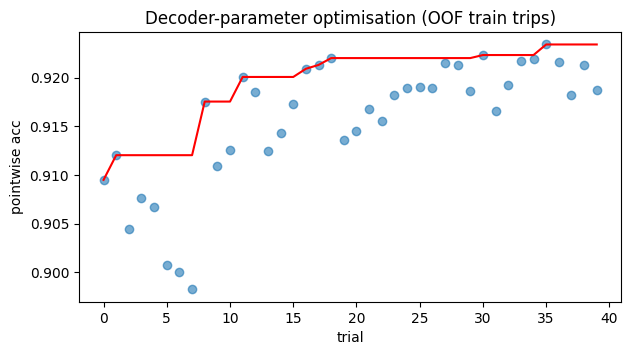

In [37]:
def hmm_space(tr):
    return dict(w_emit=tr.suggest_float("w_emit", 0.3, 3.0), hop_pen=tr.suggest_float("hop_pen", 0.1, 4.0),
                unreach_pen=tr.suggest_float("unreach_pen", 2.0, 20.0), uturn_pen=tr.suggest_float("uturn_pen", 1.0, 20.0),
                stay_pen=tr.suggest_float("stay_pen", 0.0, 2.0), max_hops=tr.suggest_int("max_hops", 2, 6),
                gap_s=tr.suggest_float("gap_s", 10.0, 120.0))
def obj(tr):
    return float(run_decoder(oof, cache, hmm_space(tr)).pointwise_acc_all.mean())
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10))
study.enqueue_trial({k: v for k, v in DEFAULT_HMM.items() if k not in ("p_floor",)})   # always evaluate the default config too
t0 = time.time(); study.optimize(obj, n_trials=N_TRIALS_HMM, callbacks=[lambda s, t: print(f"trial {t.number:3d} acc={t.value:.4f} best={s.best_value:.4f}")])
hmm_cfg = {**DEFAULT_HMM, **study.best_params}
json.dump(hmm_cfg, open(os.path.join(ARTIFACTS, "hmm_config.json"), "w"), indent=2)
study.trials_dataframe().to_csv(os.path.join(OUTPUTS, "hmm_bo_trials.csv"), index=False)
print("best decoder params:", hmm_cfg, "| time %.0f s" % (time.time() - t0))
v = study.trials_dataframe().value.to_numpy(); plt.figure(figsize=(7, 3.5)); plt.plot(v, "o", alpha=.6); plt.plot(np.maximum.accumulate(v), "r-")
plt.title("Decoder-parameter optimisation (OOF train trips)"); plt.xlabel("trial"); plt.ylabel("pointwise acc")
plt.savefig(os.path.join(FIG_DIR, "hmm_bo_progress.png"), dpi=130, bbox_inches="tight"); plt.show()

## 3. Final comparison on the 10 student_test trips (classifier-only vs classifier + HMM/Viterbi)

In [38]:
test = test.sort_values(["trip_id", "pt"]).reset_index(drop=True)
test["p"] = tuned.predict_proba(test[FEATURES])[:, 1]
rows = []; store = {}
for tid, g in test.groupby("trip_id"):
    trip = load_trip(TEST_DIR, tid); geo = TripGeometry(trip)
    path, _ = align_points_to_route(geo, trip["route"], SKIP_PEN); ref_arc = trip["route"][path]; g = g.reset_index(drop=True)
    pc = classifier_only_decode(geo, g, g.p.to_numpy()); t0 = time.time(); ph, info = viterbi_decode(geo, g, g.p.to_numpy(), hmm_cfg); dt = time.time() - t0
    a, b = route_metrics(geo, pc, ref_arc, trip["route"]), route_metrics(geo, ph, ref_arc, trip["route"])
    rows.append(dict(trip_id=tid, n_gps=geo.n_gps, **{f"clf_{k}": v for k, v in a.items()}, **{f"hmm_{k}": v for k, v in b.items()},
                     gap_resets=info["resets"], hmm_decode_s=dt))
    store[tid] = (trip, geo, ref_arc, pc, ph)
final = pd.DataFrame(rows)
final["acc_gain"] = final.hmm_pointwise_acc_all - final.clf_pointwise_acc_all
final.to_csv(os.path.join(OUTPUTS, "hmm_student_results.csv"), index=False)
cols = ["trip_id", "n_gps", "clf_pointwise_acc_all", "hmm_pointwise_acc_all", "acc_gain", "clf_arc_f1", "hmm_arc_f1", "clf_route_continuity", "hmm_route_continuity", "gap_resets"]
display(final[cols].round(4)); print(final[cols[2:]].mean(numeric_only=True).round(4))

,trip_id,n_gps,clf_pointwise_acc_all,hmm_pointwise_acc_all,acc_gain,clf_arc_f1,hmm_arc_f1,clf_route_continuity,hmm_route_continuity,gap_resets
0,00000000,2503,0.9545,0.9744,0.0200,0.9305,0.9611,0.7214,0.9833,0
1,00000007,1354,0.9904,0.9948,0.0044,0.9798,0.9878,0.9704,0.9917,0
2,00000009,1049,0.8627,0.9085,0.0458,0.8627,0.9349,0.7412,0.9600,0
3,00000040,2995,0.9536,0.9659,0.0124,0.9445,0.9886,0.7588,0.9769,0
4,00000052,262,0.9809,0.9924,0.0115,0.9040,0.9326,0.8642,0.8902,0
5,00000056,3958,0.9075,0.9603,0.0528,0.9118,0.9388,0.7357,0.9248,0
6,00000065,768,0.8568,0.8815,0.0247,0.8814,0.9722,0.7414,0.9437,1
7,00000076,1486,0.9206,0.9805,0.0599,0.8805,0.9670,0.7199,0.9490,1
8,00000077,3911,0.7949,0.9233,0.1284,0.8889,0.9925,0.7271,0.9813,0
9,00000091,874,0.8867,0.9405,0.0538,0.8479,0.8983,0.6848,0.9579,0


clf_pointwise_acc_all    0.9109
hmm_pointwise_acc_all    0.9522
acc_gain                 0.0414
clf_arc_f1               0.9032
hmm_arc_f1               0.9574
clf_route_continuity     0.7665
hmm_route_continuity     0.9559
gap_resets               0.2000
dtype: float64


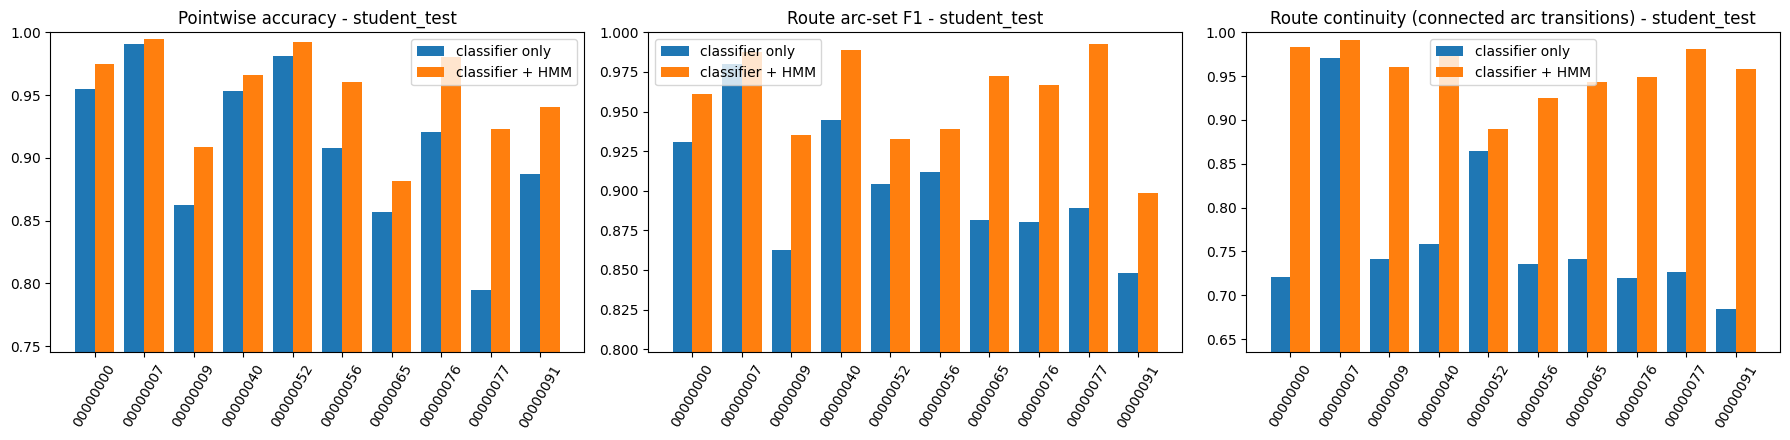

Trips where HMM did NOT help:


,trip_id,n_gps,clf_pointwise_acc_all,hmm_pointwise_acc_all,acc_gain,clf_arc_f1,hmm_arc_f1,clf_route_continuity,hmm_route_continuity,gap_resets


In [39]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5)); x = np.arange(len(final)); w = 0.4
for a, (c1, c2, t) in zip(ax, [("clf_pointwise_acc_all", "hmm_pointwise_acc_all", "Pointwise accuracy"), ("clf_arc_f1", "hmm_arc_f1", "Route arc-set F1"),
                              ("clf_route_continuity", "hmm_route_continuity", "Route continuity (connected arc transitions)")]):
    a.bar(x - w/2, final[c1], w, label="classifier only"); a.bar(x + w/2, final[c2], w, label="classifier + HMM"); a.set_title(t + " - student_test")
    a.set_xticks(x); a.set_xticklabels(final.trip_id, rotation=60); a.legend(); a.set_ylim(max(0, min(final[c1].min(), final[c2].min()) - .05), 1.0)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "hmm_vs_classifier.png"), dpi=130); plt.show()
print("Trips where HMM did NOT help:"); display(final[final.acc_gain <= 0][cols])

## 4. Ablation (which HMM ingredient matters?) - student_test, using your tuned parameters

In [40]:
variants = {"full HMM (tuned)": hmm_cfg, "no U-turn penalty": {**hmm_cfg, "uturn_pen": 0.0},
            "no invalid-transition penalty": {**hmm_cfg, "unreach_pen": 0.0, "hop_pen": 0.0},
            "emissions only (=classifier)": {**hmm_cfg, "unreach_pen": 0.0, "hop_pen": 0.0, "uturn_pen": 0.0, "stay_pen": 0.0},
            "default (untuned) HMM": DEFAULT_HMM}
abl = []
for name, P in variants.items():
    accs, conts = [], []
    for tid, (trip, geo, ref_arc, pc, ph) in store.items():
        g = test[test.trip_id == tid].reset_index(drop=True)
        pred = viterbi_decode(geo, g, g.p.to_numpy(), P)[0]; m = route_metrics(geo, pred, ref_arc, trip["route"])
        accs.append(m["pointwise_acc_all"]); conts.append(m["route_continuity"])
    abl.append(dict(variant=name, mean_pointwise_acc=np.mean(accs), mean_route_continuity=np.mean(conts)))
abl = pd.DataFrame(abl); abl.to_csv(os.path.join(OUTPUTS, "hmm_ablation.csv"), index=False); abl.round(4)

,variant,mean_pointwise_acc,mean_route_continuity
0,full HMM (tuned),0.9522,0.9559
1,no U-turn penalty,0.8887,0.9695
2,no invalid-transition penalty,0.7966,0.4820
3,emissions only (=classifier),0.9109,0.7665
4,default (untuned) HMM,0.9322,0.8999


**Your analysis (report section 5):** answer the 6 questions - hidden states, emission and transition definitions, how gaps / missing candidates are handled, what happens with disconnected segments (heavy penalty - why not -inf?), and *did the HMM improve the route?* Use the table above, and explain the trips where it did not help (inspect them on the Folium map in notebook 06).

---
# ===== 06_folium_maps.ipynb =====

# 06 - Folium route maps (report section 6)
**Partition:** `student_test`. Uses the exact same inference code as the API (`pathsnap_pipeline.PathSnapModel`).
Layers: raw GPS, road network (toggle), reference route (green), classifier-only (orange dashed), classifier+HMM (red). Open the saved HTML in a browser; screenshot one for the PDF.
**Inputs:** artifacts from notebooks 02, 04, 05 and `outputs/hmm_student_results.csv`. **Outputs:** `outputs/maps/*.html`.

In [41]:
import sys, os, json, time, warnings
sys.path.append(os.path.abspath("../src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import *

from pathsnap_core import *
from pathsnap_pipeline import PathSnapModel, score_prediction
from pathsnap_viz import make_trip_map
pm = PathSnapModel(ARTIFACTS)
res = pd.read_csv(os.path.join(OUTPUTS, "hmm_student_results.csv"), dtype={"trip_id": str})
best_trip = res.sort_values("acc_gain").trip_id.iloc[-1]; worst_trip = res.sort_values("acc_gain").trip_id.iloc[0]
print("largest HMM gain:", best_trip, "| smallest/negative gain:", worst_trip)

largest HMM gain: 00000077 | smallest/negative gain: 00000007


In [42]:
def map_for(tid, out_name):
    full = load_trip(TEST_DIR, tid)                                      # has the reference route (for drawing it)
    blind = dict(full, route=None)                                       # the pipeline never sees the route
    out = pm.predict_trip(blind); geo = out["geo"]
    layers = {"Reference route": dict(arcs=list(full["route"]), color="green", weight=6),
              "Classifier only": dict(arcs=compress(out["pred_clf"]), color="orange", weight=4, dash="6,6"),
              "Classifier + HMM (Viterbi)": dict(arcs=compress(out["pred_hmm"]), color="red", weight=3)}
    m, _ = score_prediction(geo, out["pred_hmm"], full["route"], pm.cfg["skip_pen"])
    print(tid, {k: round(v, 4) for k, v in m.items()})
    return make_trip_map(full, geo, layers, os.path.join(MAP_DIR, out_name))
map_for(best_trip, f"student_{best_trip}_hmm_best_gain.html")

00000077 {'pointwise_acc': 0.9233, 'pointwise_acc_all': 0.9233, 'arc_precision': 0.9925, 'arc_recall': 0.9925, 'arc_f1': 0.9925, 'route_continuity': 0.9813, 'n_pred_arcs': 269, 'n_ref_arcs': 268}


In [43]:
map_for(worst_trip, f"student_{worst_trip}_hmm_worst_gain.html")

00000007 {'pointwise_acc': 0.9948, 'pointwise_acc_all': 0.9948, 'arc_precision': 0.9918, 'arc_recall': 0.9837, 'arc_f1': 0.9878, 'route_continuity': 0.9917, 'n_pred_arcs': 122, 'n_ref_arcs': 123}


Open the HTML files in `outputs/maps/` in a browser, use the layer control to compare, and take a screenshot for the report. Also run `map_for(<any trip id>, 'name.html')` for any other trip you want to discuss.